In [1]:
import lightgbm as lgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, log_loss
import numpy as np
import pandas as pd
from scipy.special import iv  # modified Bessel function
import joblib
from scipy.optimize import minimize
import time
from G2Av1427 import Glicko2, Rating

In [45]:
# Recargar G2Av1427 sin reiniciar el kernel
import importlib
import G2Av1427
importlib.reload(G2Av1427)

from G2Av1427 import Glicko2, Rating

In [2]:
# Carga de los CSV
# Modelo lite
#ruta_lite = r'C:\Users\ruben\Documents\Universidad\TEG\Codigos\AplanarDatos\matches_final_model_clean_scaled.csv'
ruta_lite = r'C:\Users\ruben\Documents\Universidad\TEG\Codigos\AplanarDatos\matches_final_model_clean2.csv'
df_completo_lite = pd.read_csv(ruta_lite)
# Modelo completo
#ruta_full = r'C:\Users\ruben\Documents\Universidad\TEG\Codigos\AplanarDatos\matches_final_model_full_scaled.csv'
ruta_full = r'C:\Users\ruben\Documents\Universidad\TEG\Codigos\AplanarDatos\matches_final_model_full2.csv'
df_completo_full = pd.read_csv(ruta_full)

df_lite = df_completo_lite.copy()
df_full = df_completo_full.copy()

def chronological_split_by_ratio(df, ratio=0.7):
    """Divide el DataFrame manteniendo el orden cronológico (por match_date_from_id)."""
    df_sorted = df.sort_values('match_date_from_id').reset_index(drop=True)
    n_train = int(len(df_sorted) * ratio)
    train_df = df_sorted.iloc[:n_train].copy()
    test_df = df_sorted.iloc[n_train:].copy()
    return train_df, test_df

train_df_lite, test_df_lite = chronological_split_by_ratio(df_lite, ratio=0.7)
train_df_full, test_df_full = chronological_split_by_ratio(df_full, ratio=0.7)

print(f"Lite - Entrenamiento: {len(train_df_lite)} ({len(train_df_lite)/len(df_lite)*100:.1f}%) | Prueba: {len(test_df_lite)} ({len(test_df_lite)/len(df_lite)*100:.1f}%)")
print(f"Full - Entrenamiento: {len(train_df_full)} ({len(train_df_full)/len(df_full)*100:.1f}%) | Prueba: {len(test_df_full)} ({len(test_df_full)/len(df_full)*100:.1f}%)")

Lite - Entrenamiento: 25159 (70.0%) | Prueba: 10783 (30.0%)
Full - Entrenamiento: 17566 (70.0%) | Prueba: 7529 (30.0%)


In [6]:
# Columnas a excluir
exclude_cols = ['match_id_new', 'match_date_from_id', 'Competition', 
           'home_team', 'away_team', 'home_team_id', 'away_team_id',
           'home_goals', 'away_goals', 'home_Goals', 'away_Goals',
           'draw_prob', 'mu_home', 'mu_away', 'year_from_id', 'month_from_id']  # draw_prob aún no existe

def get_feature_cols(df):
    """Devuelve lista de columnas numéricas que no están en exclude_cols"""
    return [col for col in df.columns 
            if col not in exclude_cols and np.issubdtype(df[col].dtype, np.number)]

# Verificamos para lite y full
features_lite = get_feature_cols(df_lite)
print(f"Lite: {len(features_lite)} features")
print("Features:", features_lite[:])

features_full = get_feature_cols(df_full)
print(f"Full: {len(features_full)} features")
print("Features:", features_full[:])

Lite: 7 features
Features: ['diff_MarketValue', 'diff_NetSpending', 'diff_temperature_2m', 'diff_PiO2', 'home_Assist', 'diff_Foreign', 'home_OccRat']
Full: 10 features
Features: ['diff_MarketValue', 'diff_NetSpending', 'diff_temperature_2m', 'diff_PiO2', 'diff_xG_teo_r5', 'diff_xA_teo_r5', 'diff_DDI_r5', 'home_Assist', 'diff_Foreign', 'home_OccRat']


In [7]:
def skellam_draw_prob(mu1, mu2):
    """Probabilidad de empate según distribución de Skellam (k=0)."""
    mu1 = np.maximum(mu1, 0.0)
    mu2 = np.maximum(mu2, 0.0)
    x = 2 * np.sqrt(mu1 * mu2)
    x = np.clip(x, 0, 700)
    return np.exp(-(mu1 + mu2)) * iv(0, x)

def train_lgbm_and_add_draw_prob(train_df, test_df, model_prefix):
    """Entrena LightGBM (Poisson) y agrega mu_home, mu_away y draw_prob."""
    feature_cols = get_feature_cols(train_df)
    
    # Split interno de validacion (para early stopping sin tocar el test)
    if 'match_date_from_id' in train_df.columns:
        train_df = train_df.sort_values('match_date_from_id').reset_index(drop=True)
    val_ratio = 0.1
    n_val = max(1, int(len(train_df) * val_ratio)) if len(train_df) >= 10 else 0
    if n_val > 0:
        val_df = train_df.iloc[-n_val:].copy()
        train_main = train_df.iloc[:-n_val].copy()
    else:
        val_df = None
        train_main = train_df
    
    X_train = train_main[feature_cols]
    y_home_train = train_main['home_goals']
    y_away_train = train_main['away_goals']
    X_test = test_df[feature_cols]
    
    print(f"\n--- {model_prefix} ---")
    print(f"Entrenamiento: {len(train_df)} partidos | Prueba: {len(test_df)} partidos")
    
    if val_df is not None:
        X_val = val_df[feature_cols]
        y_home_val = val_df['home_goals']
        y_away_val = val_df['away_goals']
        eval_set_home = [(X_val, y_home_val)]
        eval_set_away = [(X_val, y_away_val)]
        callbacks = [lgb.early_stopping(10), lgb.log_evaluation(50)]
    else:
        eval_set_home = None
        eval_set_away = None
        callbacks = [lgb.log_evaluation(50)]
    
    model_home = lgb.LGBMRegressor(
        objective='poisson', metric='mae',
        n_estimators=200, learning_rate=0.05, max_depth=5,
        random_state=42, verbose=-1
    )
    model_home.fit(
        X_train, y_home_train,
        eval_set=eval_set_home,
        callbacks=callbacks
    )
    
    model_away = lgb.LGBMRegressor(
        objective='poisson', metric='mae',
        n_estimators=200, learning_rate=0.05, max_depth=5,
        random_state=42, verbose=-1
    )
    model_away.fit(
        X_train, y_away_train,
        eval_set=eval_set_away,
        callbacks=callbacks
    )
    
    # Predecir y calcular draw_prob
    X_train_full = train_df[feature_cols]
    train_df['mu_home'] = model_home.predict(X_train_full)
    train_df['mu_away'] = model_away.predict(X_train_full)
    train_df['draw_prob'] = train_df.apply(
        lambda r: skellam_draw_prob(r['mu_home'], r['mu_away']), axis=1
    )
    
    test_df['mu_home'] = model_home.predict(X_test)
    test_df['mu_away'] = model_away.predict(X_test)
    test_df['draw_prob'] = test_df.apply(
        lambda r: skellam_draw_prob(r['mu_home'], r['mu_away']), axis=1
    )
    
    full_df = pd.concat([train_df, test_df], axis=0, ignore_index=True)
    
    joblib.dump(model_home, f"{model_prefix}_home_model.pkl")
    joblib.dump(model_away, f"{model_prefix}_away_model.pkl")
    print(f"Modelos guardados: {model_prefix}_home/away_model.pkl")
    
    return full_df, model_home, model_away

In [9]:
df_lite_with_draw, model_lite_home, model_lite_away = train_lgbm_and_add_draw_prob(
    train_df_lite, test_df_lite, "lite"
 )
print("\nEstadísticas de draw_prob (lite):")
print(df_lite_with_draw['draw_prob'].describe())


--- lite ---
Entrenamiento: 25159 partidos | Prueba: 10783 partidos
Training until validation scores don't improve for 10 rounds
[50]	valid_0's l1: 0.953412
[100]	valid_0's l1: 0.943854
Early stopping, best iteration is:
[129]	valid_0's l1: 0.942042
Training until validation scores don't improve for 10 rounds
Early stopping, best iteration is:
[27]	valid_0's l1: 0.812937
Modelos guardados: lite_home/away_model.pkl

Estadísticas de draw_prob (lite):
count    35942.000000
mean         0.260422
std          0.024993
min          0.083273
25%          0.247124
50%          0.265543
75%          0.278646
max          0.318941
Name: draw_prob, dtype: float64


In [10]:
df_full_with_draw, model_full_home, model_full_away = train_lgbm_and_add_draw_prob(
    train_df_full, test_df_full, "full"
 )
print("\nEstadísticas de draw_prob (full):")
print(df_full_with_draw['draw_prob'].describe())


--- full ---
Entrenamiento: 17566 partidos | Prueba: 7529 partidos
Training until validation scores don't improve for 10 rounds
[50]	valid_0's l1: 0.972458
[100]	valid_0's l1: 0.963443
[150]	valid_0's l1: 0.960304
Early stopping, best iteration is:
[161]	valid_0's l1: 0.960268
Training until validation scores don't improve for 10 rounds
[50]	valid_0's l1: 0.852082
Early stopping, best iteration is:
[59]	valid_0's l1: 0.851495
Modelos guardados: full_home/away_model.pkl

Estadísticas de draw_prob (full):
count    25095.000000
mean         0.256051
std          0.025349
min          0.091365
25%          0.244031
50%          0.262246
75%          0.273200
max          0.342835
Name: draw_prob, dtype: float64


In [11]:
ruta_lite_out = r'C:\Users\ruben\Documents\Universidad\TEG\Codigos\AplanarDatos\matches_final_model_clean_scaled_with_draw.csv'
ruta_full_out = r'C:\Users\ruben\Documents\Universidad\TEG\Codigos\AplanarDatos\matches_final_model_full_scaled_with_draw.csv'

df_lite_with_draw.to_csv(ruta_lite_out, index=False)
df_full_with_draw.to_csv(ruta_full_out, index=False)

print(f"Lite guardado en: {ruta_lite_out}")
print(f"Full guardado en: {ruta_full_out}")

Lite guardado en: C:\Users\ruben\Documents\Universidad\TEG\Codigos\AplanarDatos\matches_final_model_clean_scaled_with_draw.csv
Full guardado en: C:\Users\ruben\Documents\Universidad\TEG\Codigos\AplanarDatos\matches_final_model_full_scaled_with_draw.csv


In [12]:
# Mostrar primeras filas de draw_prob en ambos
print("Lite - draw_prob (primeros 5):")
print(df_lite_with_draw[['year_from_id', 'home_goals', 'away_goals', 'draw_prob']].head())

print("\nFull - draw_prob (primeros 5):")
print(df_full_with_draw[['year_from_id', 'home_goals', 'away_goals', 'draw_prob']].head())

Lite - draw_prob (primeros 5):
   year_from_id  home_goals  away_goals  draw_prob
0          2019         1.0         1.0   0.271753
1          2022         1.0         1.0   0.267658
2          2024         0.0         1.0   0.265346
3          2020         4.0         1.0   0.267815
4          2024         4.0         0.0   0.265111

Full - draw_prob (primeros 5):
   year_from_id  home_goals  away_goals  draw_prob
0          2019         2.0         0.0   0.245527
1          2019         1.0         0.0   0.268366
2          2019         0.0         1.0   0.281589
3          2019         0.0         0.0   0.271455
4          2019         0.0         0.0   0.278575


In [13]:
# Si ya tienes df_lite_with_draw y df_full_with_draw en memoria, omite esta celda
# Si no, cárgalos desde los archivos guardados
import pandas as pd
import joblib

ruta_lite_out = r'C:\Users\ruben\Documents\Universidad\TEG\Codigos\AplanarDatos\matches_final_model_clean_scaled_with_draw.csv'
ruta_full_out = r'C:\Users\ruben\Documents\Universidad\TEG\Codigos\AplanarDatos\matches_final_model_full_scaled_with_draw.csv'

df_lite_with_draw = pd.read_csv(ruta_lite_out)
df_full_with_draw = pd.read_csv(ruta_full_out)

# Cargar modelos entrenados (si no están en memoria)
model_lite_home = joblib.load('lite_home_model.pkl')
model_lite_away = joblib.load('lite_away_model.pkl')
model_full_home = joblib.load('full_home_model.pkl')
model_full_away = joblib.load('full_away_model.pkl')

print("Modelos y datos cargados")

Modelos y datos cargados


In [14]:
from sklearn.metrics import mean_absolute_error

def evaluate_model(train_df, test_df, model_home, model_away, feature_cols, dataset_name):
    """
    Evalua los modelos por separado en train/test usando el split 70/30.
    """
    X_train = train_df[feature_cols]
    y_home_train = train_df['home_goals']
    y_away_train = train_df['away_goals']
    X_test = test_df[feature_cols]
    y_home_test = test_df['home_goals']
    y_away_test = test_df['away_goals']
    
    mu_home_train = model_home.predict(X_train)
    mu_away_train = model_away.predict(X_train)
    mu_home_test = model_home.predict(X_test)
    mu_away_test = model_away.predict(X_test)
    
    mae_home_train = mean_absolute_error(y_home_train, mu_home_train)
    mae_away_train = mean_absolute_error(y_away_train, mu_away_train)
    mae_home_test = mean_absolute_error(y_home_test, mu_home_test)
    mae_away_test = mean_absolute_error(y_away_test, mu_away_test)
    
    draw_prob_train = skellam_draw_prob(mu_home_train, mu_away_train)
    draw_prob_test = skellam_draw_prob(mu_home_test, mu_away_test)
    
    real_draw_train = (y_home_train == y_away_train).astype(int)
    real_draw_test = (y_home_test == y_away_test).astype(int)
    
    def log_loss_binary(prob_draw, y_true):
        prob_draw = np.clip(prob_draw, 1e-15, 1 - 1e-15)
        return -np.mean(y_true * np.log(prob_draw) + (1 - y_true) * np.log(1 - prob_draw))
    
    log_loss_train = log_loss_binary(draw_prob_train, real_draw_train)
    log_loss_test = log_loss_binary(draw_prob_test, real_draw_test)
    
    freq_draw_train = real_draw_train.mean()
    freq_draw_test = real_draw_test.mean()
    mean_pred_draw_train = draw_prob_train.mean()
    mean_pred_draw_test = draw_prob_test.mean()
    
    print(f"\n========== {dataset_name.upper()} ==========")
    print(f"MAE home  - train: {mae_home_train:.4f} | test: {mae_home_test:.4f}")
    print(f"MAE away  - train: {mae_away_train:.4f} | test: {mae_away_test:.4f}")
    print(f"LogLoss draw - train: {log_loss_train:.6f} | test: {log_loss_test:.6f}")
    print(f"Frecuencia empate real   - train: {freq_draw_train:.4f} | test: {freq_draw_test:.4f}")
    print(f"Prob. empate pred. media - train: {mean_pred_draw_train:.4f} | test: {mean_pred_draw_test:.4f}")
    
    return {
        'mae_home_train': mae_home_train, 'mae_home_test': mae_home_test,
        'mae_away_train': mae_away_train, 'mae_away_test': mae_away_test,
        'log_loss_train': log_loss_train, 'log_loss_test': log_loss_test,
        'freq_draw_train': freq_draw_train, 'freq_draw_test': freq_draw_test,
        'mean_pred_draw_train': mean_pred_draw_train, 'mean_pred_draw_test': mean_pred_draw_test
    }

In [15]:
feature_cols_lite = get_feature_cols(df_lite)
feature_cols_full = get_feature_cols(df_full)

print("Features lite:", len(feature_cols_lite))
print("Features full:", len(feature_cols_full))

Features lite: 7
Features full: 10


In [16]:
metrics_lite = evaluate_model(
    train_df_lite, test_df_lite,
    model_lite_home, model_lite_away, feature_cols_lite, 'lite'
 )
metrics_full = evaluate_model(
    train_df_full, test_df_full,
    model_full_home, model_full_away, feature_cols_full, 'full'
 )


========== LITE ==========
MAE home  - train: 0.9169 | test: 0.9366
MAE away  - train: 0.8182 | test: 0.8332
LogLoss draw - train: 0.581556 | test: 0.579284
Frecuencia empate real   - train: 0.2723 | test: 0.2683
Prob. empate pred. media - train: 0.2609 | test: 0.2592

========== FULL ==========
MAE home  - train: 0.9069 | test: 0.9406
MAE away  - train: 0.8195 | test: 0.8330
LogLoss draw - train: 0.573441 | test: 0.573717
Frecuencia empate real   - train: 0.2656 | test: 0.2615
Prob. empate pred. media - train: 0.2565 | test: 0.2551


In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

def plot_calibration(test_df, model_home, model_away, feature_cols, dataset_name):
    X_test = test_df[feature_cols]
    mu_home = model_home.predict(X_test)
    mu_away = model_away.predict(X_test)
    draw_prob = skellam_draw_prob(mu_home, mu_away)
    real_draw = (test_df['home_goals'] == test_df['away_goals']).astype(int)
    
    bins = np.linspace(0, 1, 11)
    bin_centers = (bins[:-1] + bins[1:]) / 2
    observed = []
    for i in range(len(bins) - 1):
        mask = (draw_prob >= bins[i]) & (draw_prob < bins[i + 1])
        if mask.sum() > 0:
            observed.append(real_draw[mask].mean())
        else:
            observed.append(np.nan)
    
    plt.figure(figsize=(6, 5))
    plt.plot(bin_centers, observed, 'o-', label='Observado')
    plt.plot([0, 1], [0, 1], 'k--', label='Perfectamente calibrado')
    plt.xlabel('Probabilidad de empate predicha')
    plt.ylabel('Frecuencia real de empate')
    plt.title(f'Calibración de draw_prob - {dataset_name}')
    plt.legend()
    plt.grid(True)
    plt.show()

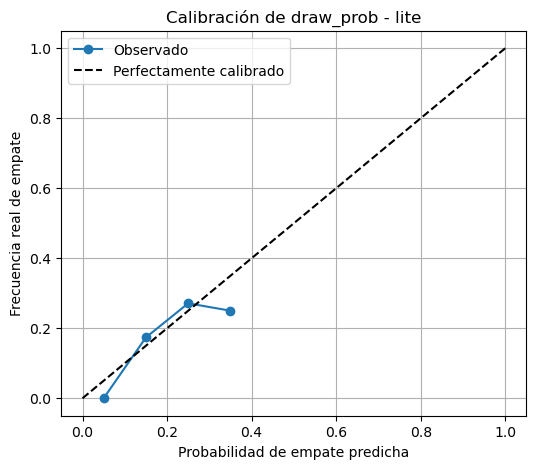

In [18]:
# Calibración para lite
plot_calibration(test_df_lite, model_lite_home, model_lite_away, feature_cols_lite, 'lite')

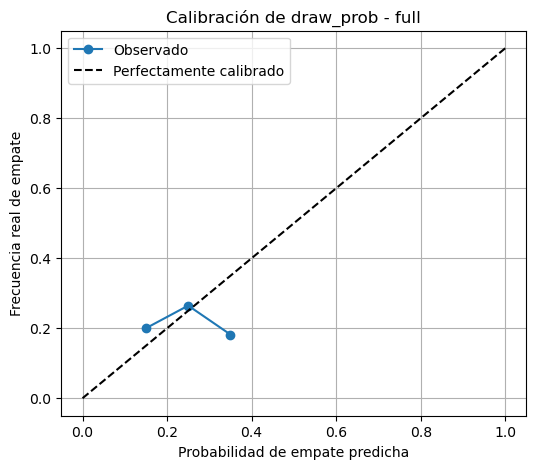

In [19]:
# Calibración para full
plot_calibration(test_df_full, model_full_home, model_full_away, feature_cols_full, 'full')

In [20]:
def plot_residuals(test_df, model_home, model_away, feature_cols, dataset_name):
    X_test = test_df[feature_cols]
    y_home_true = test_df['home_goals']
    y_away_true = test_df['away_goals']
    mu_home = model_home.predict(X_test)
    mu_away = model_away.predict(X_test)
    
    resid_home = y_home_true - mu_home
    resid_away = y_away_true - mu_away
    
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].hist(resid_home, bins=20, alpha=0.7, label='Home')
    axes[0].set_title(f'{dataset_name} - Residuos goles locales')
    axes[0].axvline(0, color='red', linestyle='--')
    axes[1].hist(resid_away, bins=20, alpha=0.7, label='Away', color='orange')
    axes[1].set_title(f'{dataset_name} - Residuos goles visitantes')
    axes[1].axvline(0, color='red', linestyle='--')
    plt.tight_layout()
    plt.show()
    
    print(f"Residuos home - media: {resid_home.mean():.3f}, std: {resid_home.std():.3f}")
    print(f"Residuos away - media: {resid_away.mean():.3f}, std: {resid_away.std():.3f}")

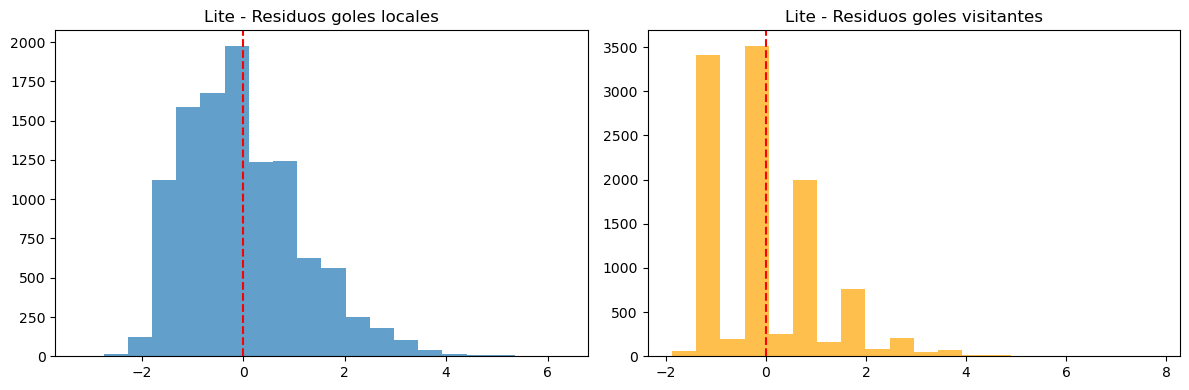

Residuos home - media: -0.011, std: 1.175
Residuos away - media: 0.034, std: 1.091


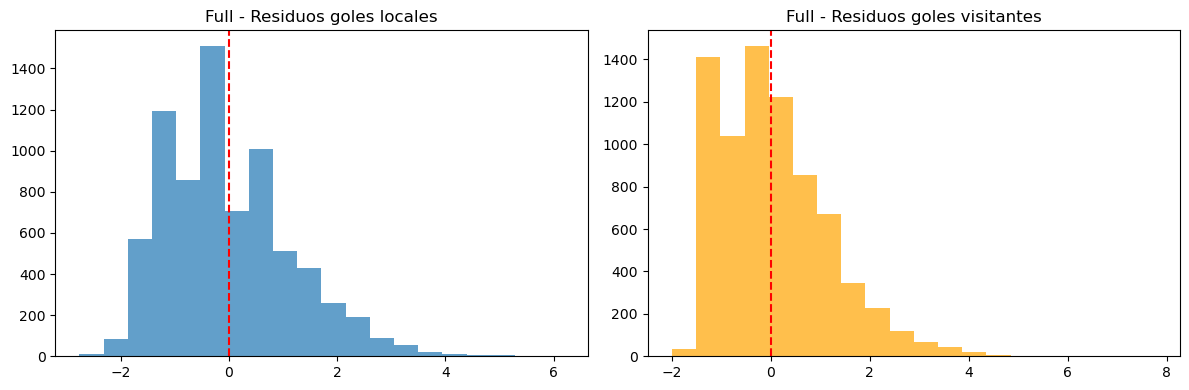

Residuos home - media: -0.022, std: 1.175
Residuos away - media: 0.044, std: 1.089


In [21]:
plot_residuals(test_df_lite, model_lite_home, model_lite_away, feature_cols_lite, 'Lite')
plot_residuals(test_df_full, model_full_home, model_full_away, feature_cols_full, 'Full')

In [28]:
def chronological_split_by_ratio(df, ratio=0.7):
    """Divide el DataFrame manteniendo el orden cronológico (por match_date_from_id)."""
    df_sorted = df.sort_values('match_date_from_id').reset_index(drop=True)
    n_train = int(len(df_sorted) * ratio)
    train_df = df_sorted.iloc[:n_train].copy()
    test_df = df_sorted.iloc[n_train:].copy()
    return train_df, test_df

# Para full
train_full, test_full = chronological_split_by_ratio(df_full_with_draw, ratio=0.7)
# Para lite
train_lite, test_lite = chronological_split_by_ratio(df_lite_with_draw, ratio=0.7)

print(f"Full - Entrenamiento: {len(train_full)} ({len(train_full)/len(df_full_with_draw)*100:.1f}%) | Prueba: {len(test_full)} ({len(test_full)/len(df_full_with_draw)*100:.1f}%)")
print(f"Lite - Entrenamiento: {len(train_lite)} ({len(train_lite)/len(df_lite_with_draw)*100:.1f}%) | Prueba: {len(test_lite)} ({len(test_lite)/len(df_lite_with_draw)*100:.1f}%)")

Full - Entrenamiento: 17566 (70.0%) | Prueba: 7529 (30.0%)
Lite - Entrenamiento: 25159 (70.0%) | Prueba: 10783 (30.0%)


In [29]:
# Reentrenar usando el split 70/30 cronológico sobre los datos con draw_prob
import joblib

result_full = train_lgbm_and_add_draw_prob(train_full, test_full, "full_retrain")
if isinstance(result_full, tuple) and len(result_full) == 3:
    df_full_reentrenado, model_full_home_r, model_full_away_r = result_full
else:
    df_full_reentrenado = result_full
    model_full_home_r = joblib.load("full_retrain_home_model.pkl")
    model_full_away_r = joblib.load("full_retrain_away_model.pkl")

result_lite = train_lgbm_and_add_draw_prob(train_lite, test_lite, "lite_retrain")
if isinstance(result_lite, tuple) and len(result_lite) == 3:
    df_lite_reentrenado, model_lite_home_r, model_lite_away_r = result_lite
else:
    df_lite_reentrenado = result_lite
    model_lite_home_r = joblib.load("lite_retrain_home_model.pkl")
    model_lite_away_r = joblib.load("lite_retrain_away_model.pkl")

Training until validation scores don't improve for 10 rounds
[50]	valid_0's l1: 0.951379
[100]	valid_0's l1: 0.942345
[150]	valid_0's l1: 0.941352
Early stopping, best iteration is:
[160]	valid_0's l1: 0.941106
Training until validation scores don't improve for 10 rounds
[50]	valid_0's l1: 0.833206
Early stopping, best iteration is:
[62]	valid_0's l1: 0.832897
Training until validation scores don't improve for 10 rounds
[50]	valid_0's l1: 0.945896
[100]	valid_0's l1: 0.936287
[150]	valid_0's l1: 0.934204
Early stopping, best iteration is:
[153]	valid_0's l1: 0.934173
Training until validation scores don't improve for 10 rounds
Early stopping, best iteration is:
[38]	valid_0's l1: 0.83063


In [30]:
def plot_calibration_from_df(df, dataset_name):
    """
    Grafica curva de calibración de draw_prob vs frecuencia real de empate.
    Asume que el DataFrame ya contiene la columna 'draw_prob'.
    """
    # Ordenar por draw_prob y crear bins
    df_sorted = df.sort_values('draw_prob').reset_index(drop=True)
    probas = df_sorted['draw_prob'].values
    real_draw = (df_sorted['home_goals'] == df_sorted['away_goals']).astype(int).values
    
    n_bins = 10
    bins = np.linspace(0, 1, n_bins+1)
    bin_centers = (bins[:-1] + bins[1:]) / 2
    observed = []
    for i in range(n_bins):
        mask = (probas >= bins[i]) & (probas < bins[i+1])
        if mask.sum() > 0:
            observed.append(real_draw[mask].mean())
        else:
            observed.append(np.nan)
    
    plt.figure(figsize=(6,5))
    plt.plot(bin_centers, observed, 'o-', label='Observado', linewidth=2, markersize=8)
    plt.plot([0,1], [0,1], 'k--', label='Perfectamente calibrado')
    plt.xlabel('Probabilidad de empate predicha (draw_prob)')
    plt.ylabel('Frecuencia real de empate')
    plt.title(f'Calibración de draw_prob - {dataset_name}')
    plt.legend()
    plt.grid(True)
    plt.show()

def plot_residuals_from_df(df, model_home, model_away, feature_cols, dataset_name):
    """
    Grafica histograma de residuos (goles reales - goles predichos) para local y visitante.
    """
    X = df[feature_cols]
    mu_home = model_home.predict(X)
    mu_away = model_away.predict(X)
    resid_home = df['home_goals'] - mu_home
    resid_away = df['away_goals'] - mu_away
    
    fig, axes = plt.subplots(1, 2, figsize=(12,4))
    axes[0].hist(resid_home, bins=30, alpha=0.7, color='blue', edgecolor='black')
    axes[0].axvline(0, color='red', linestyle='--')
    axes[0].set_title(f'{dataset_name} - Residuos goles locales')
    axes[0].set_xlabel('Residuo')
    axes[0].set_ylabel('Frecuencia')
    
    axes[1].hist(resid_away, bins=30, alpha=0.7, color='orange', edgecolor='black')
    axes[1].axvline(0, color='red', linestyle='--')
    axes[1].set_title(f'{dataset_name} - Residuos goles visitantes')
    axes[1].set_xlabel('Residuo')
    axes[1].set_ylabel('Frecuencia')
    
    plt.tight_layout()
    plt.show()
    
    print(f"Residuos home - media: {resid_home.mean():.3f}, std: {resid_home.std():.3f}")
    print(f"Residuos away - media: {resid_away.mean():.3f}, std: {resid_away.std():.3f}")

In [31]:
metrics_lite_2 = evaluate_model(
    train_lite, test_lite,
    model_lite_home_r, model_lite_away_r, feature_cols_lite, 'lite_retrain'
 )
metrics_full_2 = evaluate_model(
    train_full, test_full,
    model_full_home_r, model_full_away_r, feature_cols_full, 'full_retrain'
 )


========== LITE_RETRAIN ==========
MAE home  - train: 0.9136 | test: 0.9342
MAE away  - train: 0.8146 | test: 0.8306
LogLoss draw - train: 0.581121 | test: 0.579211
Frecuencia empate real   - train: 0.2723 | test: 0.2683
Prob. empate pred. media - train: 0.2604 | test: 0.2593

========== FULL_RETRAIN ==========
MAE home  - train: 0.9074 | test: 0.9411
MAE away  - train: 0.8189 | test: 0.8329
LogLoss draw - train: 0.573235 | test: 0.573317
Frecuencia empate real   - train: 0.2656 | test: 0.2615
Prob. empate pred. media - train: 0.2555 | test: 0.2544


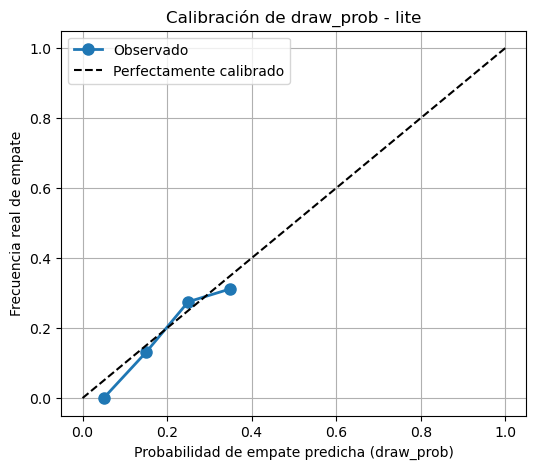

In [ ]:
plot_calibration_from_df(df_lite_reentrenado, 'lite_retrain')

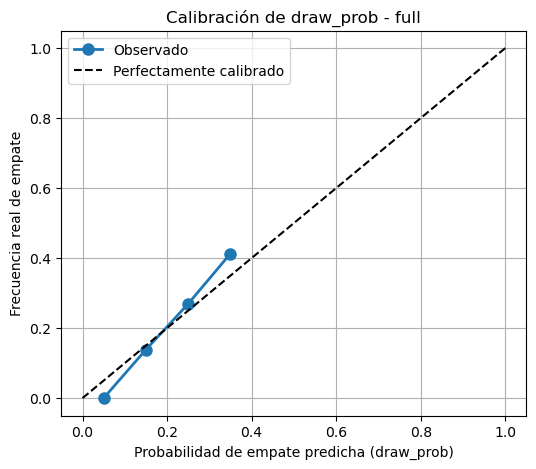

In [ ]:
plot_calibration_from_df(df_full_reentrenado, 'full_retrain')

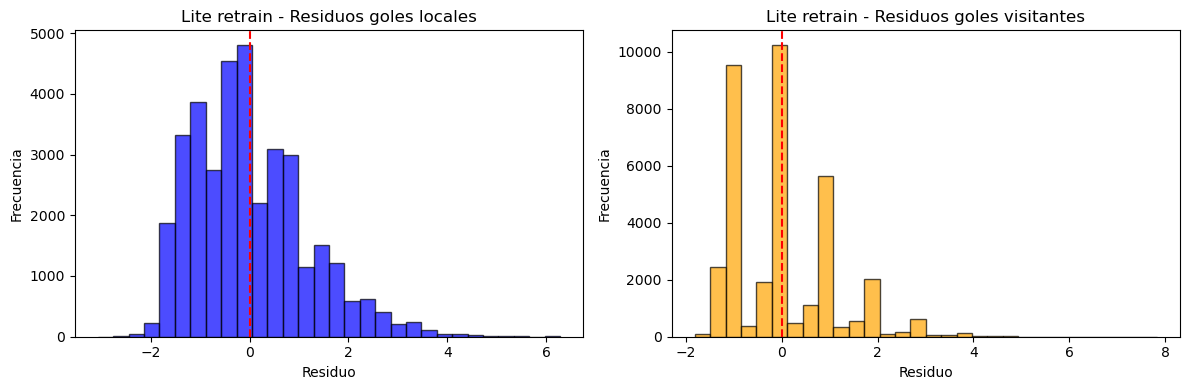

Residuos home - media: -0.001, std: 1.161
Residuos away - media: 0.012, std: 1.072


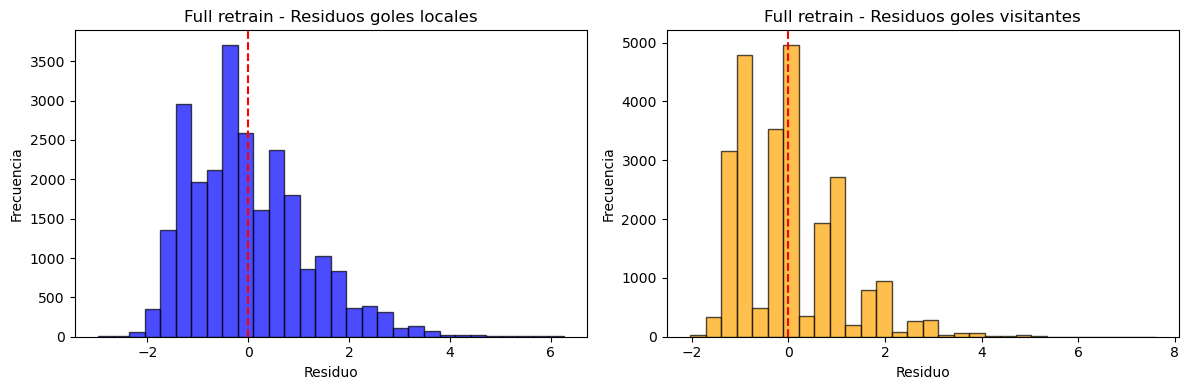

Residuos home - media: -0.007, std: 1.154
Residuos away - media: 0.012, std: 1.070


In [34]:
plot_residuals_from_df(df_lite_reentrenado, model_lite_home_r, model_lite_away_r, feature_cols_lite, 'Lite retrain')
plot_residuals_from_df(df_full_reentrenado, model_full_home_r, model_full_away_r, feature_cols_full, 'Full retrain')

In [ ]:
# === Canonical G2Av1427 training for dynamic advantage (lite/full) ===
import numpy as np

def standardize_features(df, feature_cols, stats=None, clip_value=1.0):
    df_scaled = df.copy()
    if stats is None:
        stats = {}
        for col in feature_cols:
            mean = df_scaled[col].mean()
            std = df_scaled[col].std() + 1e-8
            stats[col] = (mean, std)
    for col in feature_cols:
        mean, std = stats[col]
        z = (df_scaled[col] - mean) / std
        df_scaled[col] = np.clip(z, -clip_value, clip_value)
    return df_scaled, stats

def prepare_glicko_split(df, feature_cols, ratio=0.7):
    df_sorted = df.sort_values('match_date_from_id').reset_index(drop=True)
    n_train = int(len(df_sorted) * ratio)
    train_df = df_sorted.iloc[:n_train].copy()
    test_df = df_sorted.iloc[n_train:].copy()
    train_scaled, stats = standardize_features(train_df, feature_cols)
    test_scaled, _ = standardize_features(test_df, feature_cols, stats=stats)
    return train_scaled, test_scaled, stats

def glicko_log_loss(beta, df, feature_cols, burn_in=1000, min_prob=0.01, l2_lambda=0.01, advantage_scale=1.0):
    glicko = Glicko2(n_features=len(feature_cols))
    glicko.set_beta(beta.tolist())
    glicko.set_advantage_scale(advantage_scale)
    teams = pd.concat([df['home_team'], df['away_team']]).unique()
    ratings = {team: Rating() for team in teams}
    loss = 0.0
    count = 0
    for i, row in df.iterrows():
        home = row['home_team']
        away = row['away_team']
        feat = [row[col] for col in feature_cols]
        s_prob = row['draw_prob']
        if row['home_goals'] > row['away_goals']:
            out = 'H'
        elif row['home_goals'] < row['away_goals']:
            out = 'A'
        else:
            out = 'D'
        pw, pd_, pl = glicko.probabilities(
            ratings[home], ratings[away],
            features=feat,
            skellam_draw_probability=s_prob
        )
        if i >= burn_in:
            p_actual = pw if out == 'H' else (pl if out == 'A' else pd_)
            loss -= np.log(np.clip(p_actual, min_prob, 1.0))
            count += 1
        ratings[home], ratings[away] = glicko.rate(
            ratings[home], ratings[away],
            outcome=out,
            features=feat,
            skellam_draw_probability=s_prob
        )
    loss = loss / max(count, 1)
    l2_penalty = l2_lambda * np.sum(np.square(beta[1:]))
    return loss + l2_penalty

def evaluate_glicko(beta, train_df, test_df, feature_cols, min_prob=0.01, advantage_scale=1.0):
    glicko = Glicko2(n_features=len(feature_cols))
    glicko.set_beta(beta.tolist())
    glicko.set_advantage_scale(advantage_scale)
    teams = pd.concat([train_df['home_team'], train_df['away_team'],
                       test_df['home_team'], test_df['away_team']]).unique()
    ratings = {team: Rating() for team in teams}
    # Update ratings on train without accumulating loss
    for _, row in train_df.iterrows():
        home = row['home_team']
        away = row['away_team']
        feat = [row[col] for col in feature_cols]
        s_prob = row['draw_prob']
        if row['home_goals'] > row['away_goals']:
            out = 'H'
        elif row['home_goals'] < row['away_goals']:
            out = 'A'
        else:
            out = 'D'
        ratings[home], ratings[away] = glicko.rate(
            ratings[home], ratings[away],
            outcome=out,
            features=feat,
            skellam_draw_probability=s_prob
        )
    # Evaluate on test
    loss = 0.0
    for _, row in test_df.iterrows():
        home = row['home_team']
        away = row['away_team']
        feat = [row[col] for col in feature_cols]
        s_prob = row['draw_prob']
        if row['home_goals'] > row['away_goals']:
            out = 'H'
        elif row['home_goals'] < row['away_goals']:
            out = 'A'
        else:
            out = 'D'
        pw, pd_, pl = glicko.probabilities(
            ratings[home], ratings[away],
            features=feat,
            skellam_draw_probability=s_prob
        )
        p_actual = pw if out == 'H' else (pl if out == 'A' else pd_)
        loss -= np.log(np.clip(p_actual, min_prob, 1.0))
        ratings[home], ratings[away] = glicko.rate(
            ratings[home], ratings[away],
            outcome=out,
            features=feat,
            skellam_draw_probability=s_prob
        )
    return loss / max(len(test_df), 1)

In [42]:
# === Train dynamic advantage (lite/full) with minimize ===
burn_in_val = 1000
l2_lambda = 1e-5
min_prob = 1e-15
beta_bound = 6.0
fix_intercept = False

drop_g2a_features = {"home_Assist", "diff_NetSpending"}

feature_cols_lite_g2a = [c for c in feature_cols_lite if c not in drop_g2a_features]
feature_cols_full_g2a = [c for c in feature_cols_full if c not in drop_g2a_features]

train_lite_g, test_lite_g, stats_lite = prepare_glicko_split(
    df_lite_reentrenado, feature_cols_lite_g2a, ratio=0.7
 )
train_full_g, test_full_g, stats_full = prepare_glicko_split(
    df_full_reentrenado, feature_cols_full_g2a, ratio=0.7
 )

def build_beta(opt_beta, fix_intercept_flag):
    if fix_intercept_flag:
        return np.concatenate(([0.0], opt_beta))
    return opt_beta

print("G2A hyperparams:")
print(f"  burn_in={burn_in_val}")
print(f"  l2_lambda={l2_lambda}")
print(f"  min_prob={min_prob}")
print(f"  beta_bound=+/-{beta_bound}")
print(f"  fix_intercept={fix_intercept}")
print(f"  drop_features={sorted(drop_g2a_features)}")
print(f"Lite Glicko features: {len(feature_cols_lite_g2a)}")
print(f"Full Glicko features: {len(feature_cols_full_g2a)}")
print(f"Lite Glicko train: {len(train_lite_g)} | test: {len(test_lite_g)}")
print(f"Full Glicko train: {len(train_full_g)} | test: {len(test_full_g)}")

init_beta_lite = np.zeros(len(feature_cols_lite_g2a) + (0 if fix_intercept else 1))
bounds_lite = [(-beta_bound, beta_bound)] * len(init_beta_lite)
res_lite = minimize(
    lambda b: glicko_log_loss(
        build_beta(b, fix_intercept),
        train_lite_g,
        feature_cols_lite_g2a,
        burn_in_val,
        min_prob,
        l2_lambda,
    ),
    init_beta_lite,
    method='L-BFGS-B',
    bounds=bounds_lite,
    options={'disp': True, 'maxiter': 250}
 )
beta_lite = build_beta(res_lite.x, fix_intercept)
print(f"Lite train logloss (opt): {res_lite.fun:.6f}")
lite_test_loss = evaluate_glicko(
    beta_lite, train_lite_g, test_lite_g, feature_cols_lite_g2a, min_prob=min_prob
 )
print(f"Lite test logloss: {lite_test_loss:.6f}")
print("Lite betas:")
for name, val in zip(["Intercept"] + feature_cols_lite_g2a, beta_lite):
    print(f"  {name}: {val:.6f}")
hits_lite = np.sum((np.abs(beta_lite) >= beta_bound - 1e-8))
print(f"Lite betas at bound: {hits_lite}/{len(beta_lite)}")

init_beta_full = np.zeros(len(feature_cols_full_g2a) + (0 if fix_intercept else 1))
bounds_full = [(-beta_bound, beta_bound)] * len(init_beta_full)
res_full = minimize(
    lambda b: glicko_log_loss(
        build_beta(b, fix_intercept),
        train_full_g,
        feature_cols_full_g2a,
        burn_in_val,
        min_prob,
        l2_lambda,
    ),
    init_beta_full,
    method='L-BFGS-B',
    bounds=bounds_full,
    options={'disp': True, 'maxiter': 250}
 )
beta_full = build_beta(res_full.x, fix_intercept)
print(f"Full train logloss (opt): {res_full.fun:.6f}")
full_test_loss = evaluate_glicko(
    beta_full, train_full_g, test_full_g, feature_cols_full_g2a, min_prob=min_prob
 )
print(f"Full test logloss: {full_test_loss:.6f}")
print("Full betas:")
for name, val in zip(["Intercept"] + feature_cols_full_g2a, beta_full):
    print(f"  {name}: {val:.6f}")
hits_full = np.sum((np.abs(beta_full) >= beta_bound - 1e-8))
print(f"Full betas at bound: {hits_full}/{len(beta_full)}")

G2A hyperparams:
  burn_in=1000
  l2_lambda=1e-05
  min_prob=1e-15
  beta_bound=+/-6.0
  fix_intercept=False
  drop_features=['diff_NetSpending', 'home_Assist']
Lite Glicko features: 5
Full Glicko features: 8
Lite Glicko train: 25159 | test: 10783
Full Glicko train: 17566 | test: 7529
Lite train logloss (opt): 1.106076
Lite test logloss: 1.096073
Lite betas:
  Intercept: 6.000000
  diff_MarketValue: 0.800821
  diff_temperature_2m: -0.697501
  diff_PiO2: 0.210055
  diff_Foreign: 0.205361
  home_OccRat: 1.603185
Lite betas at bound: 1/6
Full train logloss (opt): 1.105199
Full test logloss: 1.096475
Full betas:
  Intercept: 6.000000
  diff_MarketValue: 0.432100
  diff_temperature_2m: -0.196021
  diff_PiO2: -0.105237
  diff_xG_teo_r5: 2.784140
  diff_xA_teo_r5: 0.693512
  diff_DDI_r5: -0.066351
  diff_Foreign: -0.151140
  home_OccRat: 1.372818
Full betas at bound: 1/9


In [43]:
# === G2A sweep: 4 opciones para intercepto/bounds ===
configs = [
    {"name": "baseline", "fix_intercept": False, "beta_bound": beta_bound, "l2_intercept": 0.0},
    {"name": "fix_intercept", "fix_intercept": True, "beta_bound": beta_bound, "l2_intercept": 0.0},
    {"name": "l2_intercept", "fix_intercept": False, "beta_bound": beta_bound, "l2_intercept": l2_lambda},
    {"name": "bound_8", "fix_intercept": False, "beta_bound": 8.0, "l2_intercept": 0.0},
]

def run_g2a_config(label, train_df, test_df, feature_cols, config):
    fix_i = config["fix_intercept"]
    bnd = config["beta_bound"]
    l2_i = config["l2_intercept"]
    init_beta = np.zeros(len(feature_cols) + (0 if fix_i else 1))
    bounds = [(-bnd, bnd)] * len(init_beta)

    def loss_fn(b):
        full_beta = build_beta(b, fix_i)
        base = glicko_log_loss(
            full_beta,
            train_df,
            feature_cols,
            burn_in_val,
            min_prob,
            l2_lambda,
        )
        if (not fix_i) and l2_i > 0.0:
            base += l2_i * (full_beta[0] ** 2)
        return base

    res = minimize(
        loss_fn,
        init_beta,
        method='L-BFGS-B',
        bounds=bounds,
        options={'disp': True, 'maxiter': 250},
    )
    beta = build_beta(res.x, fix_i)
    test_loss = evaluate_glicko(beta, train_df, test_df, feature_cols, min_prob=min_prob)
    hits = np.sum((np.abs(beta) >= bnd - 1e-8))
    print(f"{label} | {config['name']}")
    print(f"  train logloss: {res.fun:.6f} | test logloss: {test_loss:.6f}")
    print(f"  beta_bound=+/-{bnd} | fix_intercept={fix_i} | l2_intercept={l2_i}")
    print(f"  betas at bound: {hits}/{len(beta)}")
    print("  betas:")
    for name, val in zip(["Intercept"] + feature_cols, beta):
        print(f"    {name}: {val:.6f}")
    return {
        "beta": beta,
        "train_logloss": res.fun,
        "test_logloss": test_loss,
        "hits": int(hits),
    }

results_sweep = {"lite": {}, "full": {}}
for cfg in configs:
    results_sweep["lite"][cfg["name"]] = run_g2a_config(
        "Lite", train_lite_g, test_lite_g, feature_cols_lite_g2a, cfg
    )
    results_sweep["full"][cfg["name"]] = run_g2a_config(
        "Full", train_full_g, test_full_g, feature_cols_full_g2a, cfg
    )
    print("-" * 60)

Lite | baseline
  train logloss: 1.106076 | test logloss: 1.096073
  beta_bound=+/-6.0 | fix_intercept=False | l2_intercept=0.0
  betas at bound: 1/6
  betas:
    Intercept: 6.000000
    diff_MarketValue: 0.800821
    diff_temperature_2m: -0.697501
    diff_PiO2: 0.210055
    diff_Foreign: 0.205361
    home_OccRat: 1.603185
Full | baseline
  train logloss: 1.105199 | test logloss: 1.096475
  beta_bound=+/-6.0 | fix_intercept=False | l2_intercept=0.0
  betas at bound: 1/9
  betas:
    Intercept: 6.000000
    diff_MarketValue: 0.432100
    diff_temperature_2m: -0.196021
    diff_PiO2: -0.105237
    diff_xG_teo_r5: 2.784140
    diff_xA_teo_r5: 0.693512
    diff_DDI_r5: -0.066351
    diff_Foreign: -0.151140
    home_OccRat: 1.372818
------------------------------------------------------------
Lite | fix_intercept
  train logloss: 1.109019 | test logloss: 1.098798
  beta_bound=+/-6.0 | fix_intercept=True | l2_intercept=0.0
  betas at bound: 0/6
  betas:
    Intercept: 0.000000
    diff_Mark

In [44]:
# === G2A sweep: 3 variantes nuevas (intercepto acotado, recentrado, L2 fuerte) ===
variants = [
    {"name": "intercept_bound_2", "intercept_bound": 2.0, "recenter": False, "l2_intercept": 0.0},
    {"name": "recenter_adv", "intercept_bound": None, "recenter": True, "l2_intercept": 0.0},
    {"name": "l2_intercept_1e-3", "intercept_bound": None, "recenter": False, "l2_intercept": 1e-3},
]

def run_g2a_variant(label, train_df, test_df, feature_cols, variant):
    fix_i = False
    bnd = beta_bound
    init_beta = np.zeros(len(feature_cols) + 1)
    bounds = [(-bnd, bnd)] * len(init_beta)
    if variant["intercept_bound"] is not None:
        bounds[0] = (-variant["intercept_bound"], variant["intercept_bound"])

    def loss_fn(b):
        base = glicko_log_loss(
            b,
            train_df,
            feature_cols,
            burn_in_val,
            min_prob,
            l2_lambda,
        )
        if variant["l2_intercept"] > 0.0:
            base += variant["l2_intercept"] * (b[0] ** 2)
        return base

    res = minimize(
        loss_fn,
        init_beta,
        method='L-BFGS-B',
        bounds=bounds,
        options={'disp': True, 'maxiter': 250},
    )
    beta = res.x.copy()
    if variant["recenter"]:
        beta[0] = 0.0
    test_loss = evaluate_glicko(beta, train_df, test_df, feature_cols, min_prob=min_prob)
    hits = np.sum((np.abs(beta) >= bnd - 1e-8))
    print(f"{label} | {variant['name']}")
    print(f"  train logloss: {res.fun:.6f} | test logloss: {test_loss:.6f}")
    print(f"  beta_bound=+/-{bnd} | intercept_bound={variant['intercept_bound']}")
    print(f"  recenter={variant['recenter']} | l2_intercept={variant['l2_intercept']}")
    print(f"  betas at bound: {hits}/{len(beta)}")
    print("  betas:")
    for name, val in zip(["Intercept"] + feature_cols, beta):
        print(f"    {name}: {val:.6f}")
    return {
        "beta": beta,
        "train_logloss": res.fun,
        "test_logloss": test_loss,
        "hits": int(hits),
    }

results_variants = {"lite": {}, "full": {}}
for var in variants:
    results_variants["lite"][var["name"]] = run_g2a_variant(
        "Lite", train_lite_g, test_lite_g, feature_cols_lite_g2a, var
    )
    results_variants["full"][var["name"]] = run_g2a_variant(
        "Full", train_full_g, test_full_g, feature_cols_full_g2a, var
    )
    print("-" * 60)

Lite | intercept_bound_2
  train logloss: 1.107966 | test logloss: 1.097784
  beta_bound=+/-6.0 | intercept_bound=2.0
  recenter=False | l2_intercept=0.0
  betas at bound: 0/6
  betas:
    Intercept: 2.000000
    diff_MarketValue: 0.504553
    diff_temperature_2m: -0.267774
    diff_PiO2: 0.245092
    diff_Foreign: -0.198961
    home_OccRat: 1.760581
Full | intercept_bound_2
  train logloss: 1.107015 | test logloss: 1.098119
  beta_bound=+/-6.0 | intercept_bound=2.0
  recenter=False | l2_intercept=0.0
  betas at bound: 0/9
  betas:
    Intercept: 2.000000
    diff_MarketValue: 0.487155
    diff_temperature_2m: -0.371340
    diff_PiO2: -0.106703
    diff_xG_teo_r5: 2.532562
    diff_xA_teo_r5: 0.683961
    diff_DDI_r5: -0.150786
    diff_Foreign: -0.377301
    home_OccRat: 1.880177
------------------------------------------------------------
Lite | recenter_adv
  train logloss: 1.106076 | test logloss: 1.098745
  beta_bound=+/-6.0 | intercept_bound=None
  recenter=True | l2_intercept=0.

In [47]:
# === G2A sweep: advantage_scale + betas (sin intercepto) ===
adv_scale_bounds = (10, 100.0)
beta_bounds = (-3.0, 3.0)
init_scale = 50.0

def glicko_log_loss_scaled(beta, df, feature_cols, burn_in=1000, min_prob=1e-15, l2_lambda=1e-5, advantage_scale=1.0):
    glicko = Glicko2(n_features=len(feature_cols))
    glicko.set_beta(np.asarray(beta).tolist())
    glicko.set_advantage_scale(advantage_scale)
    teams = pd.concat([df['home_team'], df['away_team']]).unique()
    ratings = {team: Rating() for team in teams}
    loss = 0.0
    count = 0
    for i, row in df.iterrows():
        home = row['home_team']
        away = row['away_team']
        feat = [row[col] for col in feature_cols]
        s_prob = row['draw_prob']
        if row['home_goals'] > row['away_goals']:
            out = 'H'
        elif row['home_goals'] < row['away_goals']:
            out = 'A'
        else:
            out = 'D'
        pw, pd_, pl = glicko.probabilities(
            ratings[home], ratings[away],
            features=feat,
            skellam_draw_probability=s_prob
        )
        if i >= burn_in:
            p_actual = pw if out == 'H' else (pl if out == 'A' else pd_)
            loss -= np.log(np.clip(p_actual, min_prob, 1.0))
            count += 1
        ratings[home], ratings[away] = glicko.rate(
            ratings[home], ratings[away],
            outcome=out,
            features=feat,
            skellam_draw_probability=s_prob
        )
    loss = loss / max(count, 1)
    l2_penalty = l2_lambda * np.sum(np.square(np.asarray(beta)[1:]))
    return loss + l2_penalty

def evaluate_glicko_scaled(beta, train_df, test_df, feature_cols, min_prob=1e-15, advantage_scale=1.0):
    glicko = Glicko2(n_features=len(feature_cols))
    glicko.set_beta(np.asarray(beta).tolist())
    glicko.set_advantage_scale(advantage_scale)
    teams = pd.concat([train_df['home_team'], train_df['away_team'],
                       test_df['home_team'], test_df['away_team']]).unique()
    ratings = {team: Rating() for team in teams}
    for _, row in train_df.iterrows():
        home = row['home_team']
        away = row['away_team']
        feat = [row[col] for col in feature_cols]
        s_prob = row['draw_prob']
        if row['home_goals'] > row['away_goals']:
            out = 'H'
        elif row['home_goals'] < row['away_goals']:
            out = 'A'
        else:
            out = 'D'
        ratings[home], ratings[away] = glicko.rate(
            ratings[home], ratings[away],
            outcome=out,
            features=feat,
            skellam_draw_probability=s_prob
        )
    loss = 0.0
    for _, row in test_df.iterrows():
        home = row['home_team']
        away = row['away_team']
        feat = [row[col] for col in feature_cols]
        s_prob = row['draw_prob']
        if row['home_goals'] > row['away_goals']:
            out = 'H'
        elif row['home_goals'] < row['away_goals']:
            out = 'A'
        else:
            out = 'D'
        pw, pd_, pl = glicko.probabilities(
            ratings[home], ratings[away],
            features=feat,
            skellam_draw_probability=s_prob
        )
        p_actual = pw if out == 'H' else (pl if out == 'A' else pd_)
        loss -= np.log(np.clip(p_actual, min_prob, 1.0))
        ratings[home], ratings[away] = glicko.rate(
            ratings[home], ratings[away],
            outcome=out,
            features=feat,
            skellam_draw_probability=s_prob
        )
    return loss / max(len(test_df), 1)

def run_g2a_scale(label, train_df, test_df, feature_cols):
    init = np.concatenate(([init_scale], np.zeros(len(feature_cols))))
    bounds = [adv_scale_bounds] + [beta_bounds] * len(feature_cols)

    def loss_fn(x):
        scale = x[0]
        betas = x[1:]
        beta_full = np.concatenate(([0.0], betas))
        return glicko_log_loss_scaled(
            beta_full,
            train_df,
            feature_cols,
            burn_in_val,
            min_prob,
            l2_lambda,
            advantage_scale=scale,
        )

    res = minimize(
        loss_fn,
        init,
        method='L-BFGS-B',
        bounds=bounds,
        options={'disp': True, 'maxiter': 250},
    )
    scale = res.x[0]
    betas = res.x[1:]
    beta_full = np.concatenate(([0.0], betas))
    test_loss = evaluate_glicko_scaled(
        beta_full, train_df, test_df, feature_cols, min_prob=min_prob, advantage_scale=scale
    )
    adv_values = scale * (train_df[feature_cols].values @ betas)
    print(f"{label} | scale+betas")
    print(f"  train logloss: {res.fun:.6f} | test logloss: {test_loss:.6f}")
    print(f"  advantage_scale: {scale:.3f}")
    print(f"  advantage mean: {adv_values.mean():.3f} | std: {adv_values.std():.3f} | p95: {np.percentile(np.abs(adv_values), 95):.3f}")
    print("  betas:")
    for name, val in zip(feature_cols, betas):
        print(f"    {name}: {val:.6f}")
    return {
        "scale": float(scale),
        "beta": beta_full,
        "train_logloss": res.fun,
        "test_logloss": test_loss,
    }

results_scale = {"lite": {}, "full": {}}
results_scale["lite"] = run_g2a_scale(
    "Lite", train_lite_g, test_lite_g, feature_cols_lite_g2a
 )
print("-" * 60)
results_scale["full"] = run_g2a_scale(
    "Full", train_full_g, test_full_g, feature_cols_full_g2a
 )

Lite | scale+betas
  train logloss: 1.104321 | test logloss: 1.094183
  advantage_scale: 93.915
  advantage mean: 19.779 | std: 26.241 | p95: 41.485
  betas:
    diff_MarketValue: 0.159241
    diff_temperature_2m: -0.028867
    diff_PiO2: 0.022905
    diff_Foreign: -0.017278
    home_OccRat: 2.888110
------------------------------------------------------------
Full | scale+betas
  train logloss: 1.102889 | test logloss: 1.094474
  advantage_scale: 88.281
  advantage mean: 20.190 | std: 28.535 | p95: 44.757
  betas:
    diff_MarketValue: 0.094416
    diff_temperature_2m: -0.021267
    diff_PiO2: -0.034282
    diff_xG_teo_r5: 0.154021
    diff_xA_teo_r5: 0.047529
    diff_DDI_r5: -0.003348
    diff_Foreign: -0.015879
    home_OccRat: 2.844399


In [ ]:
import pandas as pd
import numpy as np

def test_loss(beta, df, feature_cols, burn_in=1000):
    # 1. Estandarizar features (crucial para el optimizador)
    df_copy = df.copy().sort_values('match_date_from_id').reset_index(drop=True)
    for col in feature_cols:
        df_copy[col] = (df_copy[col] - df_copy[col].mean()) / (df_copy[col].std() + 1e-8)

    equipos = pd.concat([df_copy['home_team'], df_copy['away_team']]).unique()
    ratings = {eq: Rating() for eq in equipos}
    
    glicko = Glicko2Dynamic(n_features=len(feature_cols), draw_correction=-0.6)
    glicko.set_beta(beta)
    
    loss = 0.0
    valid_matches = 0
    
    for i, row in df_copy.iterrows():
        home, away = row['home_team'], row['away_team']
        feat = [row[col] for col in feature_cols]
        s = row['draw_prob']
        
        if row['home_goals'] > row['away_goals']:
            out = 'H'
        elif row['home_goals'] < row['away_goals']:
            out = 'A'
        else:
            out = 'D'
            
        pw, pd_, pl = glicko.probabilities(ratings[home], ratings[away], features=feat, skellam_draw_probability=s)
        
        # 2. Burn-in period: Evaluar LogLoss solo después de que el modelo haya "calentado"
        if i >= burn_in:
            if out == 'H':
                loss -= np.log(pw)
            elif out == 'A':
                loss -= np.log(pl)
            else:
                loss -= np.log(pd_)
            valid_matches += 1
            
        # El rating siempre se actualiza, independientemente del burn-in
        ratings[home], ratings[away] = glicko.rate(ratings[home], ratings[away], outcome=out, features=feat, skellam_draw_probability=s)
        
    loss_val = loss / max(valid_matches, 1)
    print(f"Loss calculado: {loss_val:.6f}", flush=True)
    
    return loss_val

In [ ]:
import numpy as np
import pandas as pd
from scipy.optimize import minimize

# 1. DEFINICIÓN DE FEATURES (Usando tu lógica de exclusión)
exclude_cols = [
    'match_id_new', 'match_date_from_id', 'Competition', 
    'home_team', 'away_team', 'home_team_id', 'away_team_id',
    'home_goals', 'away_goals', 'home_Goals', 'away_Goals',
    'draw_prob', 'year_from_id', 'month_from_id', 'home_Assist', 'mu_home', 'mu_away'
]

def get_feature_cols(df):
    return [col for col in df.columns 
            if col not in exclude_cols and np.issubdtype(df[col].dtype, np.number)]

# Preparamos el dataset lite
df_input = df_lite_reentrenado.copy().sort_values('match_date_from_id').reset_index(drop=True)
features_lite2 = get_feature_cols(df_input)

# 2. ESTANDARIZACIÓN (Z-Score)
# Vital para que mu_home/mu_away y diff_MarketValue hablen el mismo idioma
for col in features_lite2:
    mean, std = df_input[col].mean(), df_input[col].std()
    df_input[col] = (df_input[col] - mean) / (std + 1e-8)

# 3. FUNCIÓN OBJETIVO PARA MINIMIZAR LOGLOSS
def objective_glicko_lite(beta, df, cols, burn_in):
    equipos = pd.concat([df['home_team'], df['away_team']]).unique()
    ratings = {eq: Rating() for eq in equipos}
    
    # draw_correction inicial en -0.6 para evitar el sesgo de empate
    glicko = Glicko2Dynamic(n_features=len(cols), draw_correction=-0.6)
    glicko.set_beta(beta)
    
    minprob = 0.03
    total_loss = 0.0
    valid_count = 0
    
    for i, row in df.iterrows():
        home, away = row['home_team'], row['away_team']
        feat = [row[c] for c in cols]
        s_prob = row['draw_prob']
        
        # Resultado real
        if row['home_goals'] > row['away_goals']: out = 'H'
        elif row['home_goals'] < row['away_goals']: out = 'A'
        else: out = 'D'
        
        # Probabilidades antes de actualizar
        pw, pd_, pl = glicko.probabilities(ratings[home], ratings[away], features=feat, skellam_draw_probability=s_prob)
        
        # LogLoss después del burn-in (periodo de gracia para el Elo)
        if i >= burn_in:
            p_actual = pw if out == 'H' else (pl if out == 'A' else pd_)
            # total_loss -= np.log(np.clip(p_actual, 1e-15, 1.0))
            total_loss -= np.log(np.clip(p_actual, minprob, 1.0))
            valid_count += 1
            
        # Actualización de Glicko
        ratings[home], ratings[away] = glicko.rate(ratings[home], ratings[away], outcome=out, features=feat, skellam_draw_probability=s_prob)
    
    # Al final de tu def objective_glicko_lite:
    logloss_promedio = total_loss / max(valid_count, 1)
    
    # Penalidad L2 (lambda = 0.01) para encoger los betas
    l2_penalty = 0.01 * np.sum(np.square(beta)) 
    
    return logloss_promedio + l2_penalty

    return total_loss / max(valid_count, 1)

# 4. EJECUCIÓN DEL OPTIMIZADOR
# Beta inicial: Intercepto + 11 coeficientes para Lite
initial_beta = [0.0] * (len(features_lite2) + 1)
burn_in_val = 1000 

print(f"Optimizando con {len(features_lite2)} features (incluyendo mu_home/mu_away)...")

res_lite = minimize(
    objective_glicko_lite,
    initial_beta,
    args=(df_input, features_lite2, burn_in_val),
    method='L-BFGS-B',
    options={'disp': True, 'maxiter': 50}
)

print("-" * 30)
print(f"LogLoss Final Lite: {res_lite.fun:.6f}")
print("Coeficientes Óptimos (Betas):")
for name, val in zip(['Intercept'] + features_lite2, res_lite.x):
    print(f"  {name}: {val:.4f}")

In [ ]:
import numpy as np
import pandas as pd
from scipy.optimize import minimize

# 1. DEFINIR FEATURES EXCLUSIVAS PARA GLICKO (Adiós multicolinealidad)
# Solo le pasamos el resumen del LightGBM y el clima del momento
features_glicko_lite = ['diff_temperature_2m', 'diff_PiO2', 'mu_home', 'mu_away']

# (Para cuando corras el modelo Full, usarás algo similar)
# features_glicko_full = ['diff_temperature_2m', 'diff_PiO2', 'mu_home', 'mu_away']

df_input = df_lite_reentrenado.copy().sort_values('match_date_from_id').reset_index(drop=True)

# 2. ESTANDARIZACIÓN (Solo a las features de Glicko)
for col in features_glicko_lite:
    mean, std = df_input[col].mean(), df_input[col].std()
    df_input[col] = (df_input[col] - mean) / (std + 1e-8)

# 3. FUNCIÓN OBJETIVO CON REGULARIZACIÓN Y LÍMITES
def objective_glicko_lite(beta, df, cols, burn_in):
    equipos = pd.concat([df['home_team'], df['away_team']]).unique()
    ratings = {eq: Rating() for eq in equipos}
    
    glicko = Glicko2Dynamic(n_features=len(cols), draw_correction=-0.6)
    glicko.set_beta(beta)
    
    total_loss = 0.0
    valid_count = 0
    
    for i, row in df.iterrows():
        home, away = row['home_team'], row['away_team']
        feat = [row[c] for c in cols]
        s_prob = row['draw_prob']
        
        if row['home_goals'] > row['away_goals']: out = 'H'
        elif row['home_goals'] < row['away_goals']: out = 'A'
        else: out = 'D'
        
        pw, pd_, pl = glicko.probabilities(ratings[home], ratings[away], features=feat, skellam_draw_probability=s_prob)
        
        if i >= burn_in:
            p_actual = pw if out == 'H' else (pl if out == 'A' else pd_)
            # MEJORA A: Limitar la probabilidad mínima al 3% (el fútbol es impredecible)
            total_loss -= np.log(np.clip(p_actual, 0.03, 1.0))
            valid_count += 1
            
        ratings[home], ratings[away] = glicko.rate(ratings[home], ratings[away], outcome=out, features=feat, skellam_draw_probability=s_prob)
    
    logloss_base = total_loss / max(valid_count, 1)
    
    # MEJORA B: Penalidad Ridge (L2) para evitar Betas gigantes
    l2_penalty = 0.02 * np.sum(np.square(beta[1:])) # Penalizamos los coeficientes, no el intercepto
    
    return logloss_base + l2_penalty

# 4. EJECUCIÓN (Ahora con solo 4 variables + Intercepto)
initial_beta = [0.0] * (len(features_glicko_lite) + 1)
burn_in_val = 1000 

print(f"Optimizando con {len(features_glicko_lite)} features limpias...")

res_lite = minimize(
    objective_glicko_lite,
    initial_beta,
    args=(df_input, features_glicko_lite, burn_in_val),
    method='L-BFGS-B',
    options={'disp': True, 'maxiter': 60}
)

print("-" * 30)
# Mostramos el LogLoss real (sin la penalidad L2)
print(f"LogLoss Final Lite: {res_lite.fun - (0.02 * np.sum(np.square(res_lite.x[1:]))):.6f}")
print("Coeficientes Óptimos (Betas):")
for name, val in zip(['Intercept'] + features_glicko_lite, res_lite.x):
    print(f"  {name}: {val:.4f}")

In [ ]:
def objective_glicko_shelopugin(beta_params, df, feature_cols, burn_in):
    # Inicializar ratings
    equipos = pd.concat([df['home_team'], df['away_team']]).unique()
    ratings = {eq: Rating() for eq in equipos}
    
    # El modelo recibe n_features (sin contar intercepto ni alpha)
    model = Glicko2Dynamic(n_features=len(feature_cols))
    model.set_beta(beta_params)
    
    total_loss = 0.0
    count = 0
    
    for i, row in df.iterrows():
        home, away = row['home_team'], row['away_team']
        feats = [row[c] for c in feature_cols]
        skellam = row['draw_prob']
        
        # 1. Calcular Probabilidades (antes de actualizar)
        p_win, p_tie, p_loss = model.probabilities(ratings[home], ratings[away], feats, skellam)
        
        # 2. LogLoss (Solo después del burn-in)
        if i >= burn_in:
            if row['home_goals'] > row['away_goals']:
                prob = p_win
            elif row['home_goals'] < row['away_goals']:
                prob = p_loss
            else:
                prob = p_tie
            
            total_loss -= log(max(prob, 0.03)) # Clip en 3% para realismo futbolístico
            count += 1
        
        # 3. Actualizar Ratings
        out = 'H' if row['home_goals'] > row['away_goals'] else ('A' if row['home_goals'] < row['away_goals'] else 'D')
        ratings[home], ratings[away] = model.rate(ratings[home], ratings[away], out, feats, skellam_draw_probability=skellam)
    
    # Regularización L2 para estabilidad de los Betas (OPTA Style)
    l2_reg = 0.001 * np.sum(np.square(beta_params))
    
    return (total_loss / count) + l2_reg

In [ ]:
import numpy as np
import pandas as pd
from scipy.optimize import minimize

# 1. DEFINICIÓN DE FEATURES (Contexto Puro + Ventaja Dinámica)
# Eliminamos los rankings mu_home/away de aquí para que Glicko los maneje por su cuenta
feature_cols = [
    'diff_MarketValue', 
    'diff_NetSpending', 
    'diff_temperature_2m', 
    'diff_PiO2', 
    'diff_Foreign', 
    'home_OccRat'
]

# 2. PREPARACIÓN Y ESTANDARIZACIÓN
df_input = df_lite_reentrenado.copy().sort_values('match_id_new').reset_index(drop=True)

# Estandarizamos todas las features para que la regularización L2 sea equitativa
scaler_stats = {}
for col in feature_cols:
    mean, std = df_input[col].mean(), df_input[col].std()
    df_input[col] = (df_input[col] - mean) / (std + 1e-8)
    scaler_stats[col] = (mean, std)

# 3. FUNCIÓN OBJETIVO CON CONTROL DE SOBREAJUSTE (SHELOPUGIN-SIROTKIN STYLE)
def objective_glicko_shelopugin(beta_params, df, cols, burn_in, l2_lambda=0.01):
    """
    beta_params: [intercept, beta1, ..., betaN, alpha]
    l2_lambda: Parámetro de regularización para evitar sobreajuste.
    """
    equipos = pd.concat([df['home_team'], df['away_team']]).unique()
    ratings = {eq: Rating() for eq in equipos}
    
    # El modelo se inicializa con n_features (beta_params tiene intercepto y alpha adicionales)
    model = Glicko2Dynamic(n_features=len(cols))
    model.set_beta(beta_params)
    
    total_loss = 0.0
    count = 0
    
    for i, row in df.iterrows():
        home, away = row['home_team'], row['away_team']
        feats = [row[c] for c in cols]
        skellam = row['draw_prob']
        
        # Probabilidades actuales (antes de actualizar el rating con el resultado)
        p_win, p_tie, p_loss = model.probabilities(ratings[home], ratings[away], feats, skellam)
        
        if i >= burn_in:
            if row['home_goals'] > row['away_goals']:
                prob = p_win
            elif row['home_goals'] < row['away_goals']:
                prob = p_loss
            else:
                prob = p_tie
            
            # Clip para estabilidad numérica
            total_loss -= np.log(np.clip(prob, 0.01, 0.99))
            count += 1
        
        # Actualización de Ratings (Aprendizaje del modelo)
        out = 'H' if row['home_goals'] > row['away_goals'] else ('A' if row['home_goals'] < row['away_goals'] else 'D')
        ratings[home], ratings[away] = model.rate(ratings[home], ratings[away], out, feats, skellam_draw_probability=skellam)
    
    # LogLoss base
    base_loss = total_loss / count
    
    # PENALIZACIÓN L2: Evita que los Betas crezcan sin control (Sobreajuste)
    # No penalizamos el intercepto (beta[0]) ni el alpha de empate (beta[-1])
    reg_term = l2_lambda * np.sum(np.square(beta_params[1:-1]))
    
    return base_loss + reg_term

# 4. EJECUCIÓN DE LA OPTIMIZACIÓN
# [Intercepto, 6 features, Alpha] = 8 parámetros
initial_beta = [0.0] * (len(feature_cols) + 2)
burn_in_val = 1000 

print(f"Optimizando modelo G2S (Shelopugin-Sirotkin) con {len(feature_cols)} features...")
print(f"Control de sobreajuste activo (L2 Regularization).")

res = minimize(
    objective_glicko_shelopugin,
    initial_beta,
    args=(df_input, feature_cols, burn_in_val, 0.01), # l2_lambda=0.01
    method='L-BFGS-B',
    options={'disp': True, 'maxiter': 80}
)

# 5. RESULTADOS
print("-" * 50)
logloss_final = res.fun - (0.01 * np.sum(np.square(res.x[1:-1])))
print(f"✅ LogLoss Final (Sin penalidad): {logloss_final:.6f}")

print("\n📈 Coeficientes de la Ecuación de Ventaja:")
nombres = ['Intercepto'] + feature_cols + ['Alpha (Empate)']
for nom, val in zip(nombres, res.x):
    print(f"  {nom.ljust(25)}: {val:.5f}")

In [ ]:
import numpy as np
import pandas as pd
from scipy.optimize import minimize

# 1. CONFIGURACIÓN DE VARIABLES
# Usamos tu DataFrame y tus columnas específicas
df_final = df_lite_reentrenado.copy().sort_values('match_date_from_id').reset_index(drop=True)
features_lite = [col for col in df_final.columns if col not in ['home_team', 'away_team', 'home_goals', 'away_goals', 'match_date_from_id', 'draw_prob', 'Competition']] 
# ^ Asegúrate de que features_lite solo contenga las numéricas para Glicko

burn_in_period = 1000  # Saltamos los primeros 1000 partidos para dejar que el Elo se calibre

# 2. ESTANDARIZACIÓN PREVIA (Crucial para que el optimizador no explote)
for col in features_lite:
    df_final[col] = (df_final[col] - df_final[col].mean()) / (df_final[col].std() + 1e-8)

# 3. FUNCIÓN OBJETIVO (LogLoss)
def objective_glicko(beta, df, cols, burn_in):
    equipos = pd.concat([df['home_team'], df['away_team']]).unique()
    ratings = {eq: Rating() for eq in equipos}
    
    # Inicializamos con draw_correction de -0.6 para balancear la prob. de empate
    glicko = Glicko2Dynamic(n_features=len(cols), draw_correction=-0.6)
    glicko.set_beta(beta)
    
    total_loss = 0.0
    valid_count = 0
    
    for i, row in df.iterrows():
        home, away = row['home_team'], row['away_team']
        feat = [row[c] for c in cols]
        s_prob = row['draw_prob']
        
        # Resultado real
        if row['home_goals'] > row['away_goals']: out = 'H'
        elif row['home_goals'] < row['away_goals']: out = 'A'
        else: out = 'D'
        
        # Probabilidades actuales del modelo
        pw, pd_, pl = glicko.probabilities(ratings[home], ratings[away], features=feat, skellam_draw_probability=s_prob)
        
        # Cálculo de LogLoss post burn-in
        if i >= burn_in:
            p_actual = pw if out == 'H' else (pl if out == 'A' else pd_)
            total_loss -= np.log(np.clip(p_actual, 1e-15, 1.0))
            valid_count += 1
            
        # Actualización de ratings (siempre ocurre)
        ratings[home], ratings[away] = glicko.rate(ratings[home], ratings[away], outcome=out, features=feat, skellam_draw_probability=s_prob)
    
    return total_loss / max(valid_count, 1)

# 4. EJECUCIÓN
# [Intercepto, beta1, beta2, ...]
initial_beta = [0.0] * (len(features_lite) + 1)

print("Optimizando parámetros para el modelo LITE...")
resultado = minimize(
    objective_glicko,
    initial_beta,
    args=(df_final, features_lite, burn_in_period),
    method='L-BFGS-B',
    options={'disp': True, 'maxiter': 40}
)

print("-" * 30)
print(f"LogLoss Final: {resultado.fun:.6f}")
print(f"Betas (Coeficientes): {resultado.x}")

In [ ]:
def glicko_log_loss(beta, df, feature_cols):
    """
    beta: lista de coeficientes (intercepto + betas de features)
    df: DataFrame con columnas necesarias (ordenado cronológicamente)
    feature_cols: lista de nombres de columnas a usar como features
    """
    # Ordenar por fecha si no lo está
    df = df.sort_values('match_date_from_id').reset_index(drop=True)
    
    # Inicializar ratings para todos los equipos
    equipos = pd.concat([df['home_team'], df['away_team']]).unique()
    ratings = {equipo: Rating() for equipo in equipos}
    
    # Crear modelo
    glicko = Glicko2Dynamic(n_features=len(feature_cols))
    glicko.set_beta(beta)
    
    loss = 0.0
    for _, row in df.iterrows():
        home = row['home_team']
        away = row['away_team']
        feat = [row[col] for col in feature_cols]
        s = row['draw_prob']
        
        # Resultado real
        if row['home_goals'] > row['away_goals']:
            out = 'H'
        elif row['home_goals'] < row['away_goals']:
            out = 'A'
        else:
            out = 'D'
        
        # Probabilidades
        pw, pd_, pl = glicko.probabilities(
            ratings[home], ratings[away],
            features=feat,
            skellam_draw_probability=s
        )
        
        # Log loss
        if out == 'H':
            loss -= np.log(pw)
        elif out == 'A':
            loss -= np.log(pl)
        else:
            loss -= np.log(pd_)
        
        # Actualizar ratings
        ratings[home], ratings[away] = glicko.rate(
            ratings[home], ratings[away],
            outcome=out,
            features=feat,
            skellam_draw_probability=s
        )
    
    return loss / len(df)

In [ ]:
def chronological_mask(df, ratio=0.7):
    df_sorted = df.sort_values('match_date_from_id').reset_index(drop=True)
    n_train = int(len(df_sorted) * ratio)
    train_mask = np.zeros(len(df_sorted), dtype=bool)
    train_mask[:n_train] = True
    return train_mask

train_mask_lite = chronological_mask(df_lite_reentrenado)
train_mask_full = chronological_mask(df_full_reentrenado)

df_lite_train = df_lite_reentrenado[train_mask_lite].copy()
df_lite_test = df_lite_reentrenado[~train_mask_lite].copy()
df_full_train = df_full_reentrenado[train_mask_full].copy()
df_full_test = df_full_reentrenado[~train_mask_full].copy()

print(f"Lite train: {len(df_lite_train)} | test: {len(df_lite_test)}")
print(f"Full train: {len(df_full_train)} | test: {len(df_full_test)}")

# =================================================================
# FEATURES
# =================================================================
exclude_cols = ['match_id_new', 'match_date_from_id', 'Competition', 'home_team', 'away_team',
                'home_team_id', 'away_team_id', 'home_goals', 'away_goals',
                'home_Goals', 'away_Goals', 'draw_prob', 'mu_home', 'mu_away']

feature_cols_lite = [col for col in df_lite_train.columns 
                     if col not in exclude_cols and np.issubdtype(df_lite_train[col].dtype, np.number)]
feature_cols_full = [col for col in df_full_train.columns 
                     if col not in exclude_cols and np.issubdtype(df_full_train[col].dtype, np.number)]

print("Features lite:", feature_cols_lite)
print("Features full:", feature_cols_full)


In [ ]:
def evaluate_test(beta, df_train, df_test, feature_cols):
    """
    beta: lista de coeficientes (intercepto + betas de features)
    df_train: DataFrame de entrenamiento (debe tener columna 'draw_prob', 'home_goals', 'away_goals', etc.)
    df_test: DataFrame de prueba (mismas columnas)
    feature_cols: lista de nombres de columnas a usar como features
    """
    # Asegurar orden cronológico
    df_train = df_train.sort_values('match_date_from_id').reset_index(drop=True)
    df_test = df_test.sort_values('match_date_from_id').reset_index(drop=True)
    
    # Inicializar ratings con todos los equipos que aparecen en train y test
    equipos_train = pd.concat([df_train['home_team'], df_train['away_team']]).unique()
    equipos_test = pd.concat([df_test['home_team'], df_test['away_team']]).unique()
    todos_equipos = np.unique(np.concatenate([equipos_train, equipos_test]))
    ratings = {equipo: Rating() for equipo in todos_equipos}
    
    # Crear modelo y fijar betas
    glicko = Glicko2Dynamic(n_features=len(feature_cols))
    glicko.set_beta(beta)
    
    # ---- Recorrer entrenamiento sin acumular pérdida (solo actualizar ratings) ----
    for _, row in df_train.iterrows():
        home = row['home_team']
        away = row['away_team']
        feat = [row[col] for col in feature_cols]
        s = row['draw_prob']
        
        if row['home_goals'] > row['away_goals']:
            out = 'H'
        elif row['home_goals'] < row['away_goals']:
            out = 'A'
        else:
            out = 'D'
        
        # Actualizar (no necesitamos las probabilidades)
        ratings[home], ratings[away] = glicko.rate(
            ratings[home], ratings[away],
            outcome=out,
            features=feat,
            skellam_draw_probability=s
        )
    
    # ---- Recorrer prueba acumulando pérdida ----
    loss = 0.0
    for _, row in df_test.iterrows():
        home = row['home_team']
        away = row['away_team']
        feat = [row[col] for col in feature_cols]
        s = row['draw_prob']
        
        if row['home_goals'] > row['away_goals']:
            out = 'H'
        elif row['home_goals'] < row['away_goals']:
            out = 'A'
        else:
            out = 'D'
        
        # Probabilidades
        pw, pd_, pl = glicko.probabilities(
            ratings[home], ratings[away],
            features=feat,
            skellam_draw_probability=s
        )
        
        # Log loss
        if out == 'H':
            loss -= np.log(pw)
        elif out == 'A':
            loss -= np.log(pl)
        else:
            loss -= np.log(pd_)
        
        # Actualizar ratings también en prueba (para mantener coherencia con la secuencia real)
        ratings[home], ratings[away] = glicko.rate(
            ratings[home], ratings[away],
            outcome=out,
            features=feat,
            skellam_draw_probability=s
        )
    
    return loss / len(df_test)

In [ ]:
call_counter = 0

def glicko_log_loss_debug(beta, df, feature_cols):
    global call_counter
    call_counter += 1
    """
    beta: lista de coeficientes (intercepto + betas de features)
    df: DataFrame con columnas necesarias (ordenado cronológicamente)
    feature_cols: lista de nombres de columnas a usar como features
    """
    # Ordenar por fecha si no lo está
    df = df.sort_values('match_date_from_id').reset_index(drop=True)
    
    # Inicializar ratings para todos los equipos
    equipos = pd.concat([df['home_team'], df['away_team']]).unique()
    ratings = {equipo: Rating() for equipo in equipos}
    
    # Crear modelo
    glicko = Glicko2Dynamic(n_features=len(feature_cols))
    glicko.set_beta(beta)
    
    loss = 0.0
    for _, row in df.iterrows():
        home = row['home_team']
        away = row['away_team']
        feat = [row[col] for col in feature_cols]
        s = row['draw_prob']
        
        # Resultado real
        if row['home_goals'] > row['away_goals']:
            out = 'H'
        elif row['home_goals'] < row['away_goals']:
            out = 'A'
        else:
            out = 'D'
        
        # Probabilidades
        pw, pd_, pl = glicko.probabilities(
            ratings[home], ratings[away],
            features=feat,
            skellam_draw_probability=s
        )
        
        # Log loss
        if out == 'H':
            loss -= np.log(pw)
        elif out == 'A':
            loss -= np.log(pl)
        else:
            loss -= np.log(pd_)
        
        # Actualizar ratings
        ratings[home], ratings[away] = glicko.rate(
            ratings[home], ratings[away],
            outcome=out,
            features=feat,
            skellam_draw_probability=s
        )
    
    return loss / len(df)
    loss_val = loss / len(df)
    print(f"Evaluación {call_counter}: pérdida = {loss_val:.6f}")
    return loss_val

In [ ]:
df_sample = df_lite_train.head(100)
res_test = minimize(lambda b: glicko_log_loss(b, df_sample, features_lite),
                    initial_beta, method='L-BFGS-B', options={'maxiter': 5, 'disp': True})

In [ ]:
import sys

def test_loss(beta, df, feature_cols):
    print("Dentro de test_loss", flush=True)
    # Copia simplificada de glicko_log_loss, pero con prints
    df = df.sort_values('match_date_from_id').reset_index(drop=True)
    equipos = pd.concat([df['home_team'], df['away_team']]).unique()
    ratings = {eq: Rating() for eq in equipos}
    glicko = Glicko2Dynamic(n_features=len(feature_cols))
    glicko.set_beta(beta)
    loss = 0.0
    for i, row in df.iterrows():
        if i % 500 == 0:
            print(f"Procesando partido {i}...", flush=True)
        home, away = row['home_team'], row['away_team']
        feat = [row[col] for col in feature_cols]
        s = row['draw_prob']
        if row['home_goals'] > row['away_goals']:
            out = 'H'
        elif row['home_goals'] < row['away_goals']:
            out = 'A'
        else:
            out = 'D'
        pw, pd_, pl = glicko.probabilities(ratings[home], ratings[away], features=feat, skellam_draw_probability=s)
        if out == 'H':
            loss -= np.log(pw)
        elif out == 'A':
            loss -= np.log(pl)
        else:
            loss -= np.log(pd_)
        ratings[home], ratings[away] = glicko.rate(ratings[home], ratings[away], outcome=out, features=feat, skellam_draw_probability=s)
    loss_val = loss / len(df)
    print(f"Loss calculado: {loss_val:.6f}", flush=True)
    return loss_val

# Usar una muestra pequeña (primeros 100 partidos)
df_sample = df_lite_train.head(100)
initial_beta = np.zeros(len(features_lite)+1)
loss_value = test_loss(initial_beta, df_sample, features_lite)
print("Prueba completada. Loss:", loss_value)

In [ ]:
from scipy.optimize import minimize

res = minimize(lambda b: test_loss(b, df_sample, features_lite),
               initial_beta, method='L-BFGS-B', options={'maxiter': 20, 'disp': True})
print(res)

In [ ]:
# Tomar una muestra de entrenamiento de 1000 partidos (los primeros, cronológicos)
df_train_sample = df_lite_train.head(1000).copy()

# Optimización sobre la muestra
initial_beta = np.zeros(len(features_lite)+1)
res = minimize(
    lambda b: test_loss(b, df_train_sample, features_lite),
    initial_beta,
    method='L-BFGS-B',
    options={'maxiter': 50, 'disp': True}
)
beta_opt = res.x
print("Betas óptimos:", beta_opt)
print("LogLoss final en muestra de entrenamiento:", res.fun)

# Evaluar en el conjunto de prueba completo
test_loss_dyn = evaluate_test(beta_opt, df_lite_train, df_lite_test, features_lite)
print(f"Test LogLoss (ventaja dinámica): {test_loss_dyn:.6f}")

# Baseline
beta_zero = np.zeros(len(features_lite)+1)
test_loss_base = evaluate_test(beta_zero, df_lite_train, df_lite_test, features_lite)
print(f"Test LogLoss (baseline): {test_loss_base:.6f}")
print(f"Mejora en test: {test_loss_base - test_loss_dyn:.6f}")

In [ ]:
def base_log_loss(df, tau=0.8, draw_correction=0.3):
    glicko = Glicko2Dynamic(tau=tau, draw_correction=draw_correction, n_features=0)
    # beta solo el intercepto (no se usa porque advantage=0)
    glicko.set_beta([0.0])
    df = df.sort_values('match_date_from_id').reset_index(drop=True)
    equipos = pd.concat([df['home_team'], df['away_team']]).unique()
    ratings = {eq: Rating() for eq in equipos}
    loss = 0.0
    for _, row in df.iterrows():
        home, away = row['home_team'], row['away_team']
        s = row['draw_prob']
        if row['home_goals'] > row['away_goals']:
            out = 'H'
        elif row['home_goals'] < row['away_goals']:
            out = 'A'
        else:
            out = 'D'
        # OJO: sin features, pasamos features=None y advantage=None
        pw, pd_, pl = glicko.probabilities(ratings[home], ratings[away], features=None, skellam_draw_probability=s)
        if out == 'H':
            loss -= np.log(pw)
        elif out == 'A':
            loss -= np.log(pl)
        else:
            loss -= np.log(pd_)
        # rate también sin features
        ratings[home], ratings[away] = glicko.rate(ratings[home], ratings[away], outcome=out, features=None, skellam_draw_probability=s)
    return loss / len(df)

In [ ]:
# Usa df_lite_train (entero) o una muestra grande
df_train = df_lite_train  # todo el entrenamiento (~25k partidos) o head(5000)

for tau in [0.5, 0.8, 1.0, 1.2, 1.5]:
    for dc in [-0.4, -0.2, 0.0, 0.2, 0.4]:
        loss = base_log_loss(df_train, tau=tau, draw_correction=dc)
        print(f"tau={tau}, dc={dc:.1f} -> {loss:.6f}")

In [ ]:
# Tomar una muestra del entrenamiento (primeros N partidos)
N = 5000
df_train_sample = df_lite_train.head(N).copy()

# Optimización sobre la muestra
initial_beta = np.zeros(len(features_lite) + 1)
result = minimize(
    lambda b: glicko_log_loss(b, df_train_sample, features_lite),
    initial_beta,
    method='L-BFGS-B',
    options={'maxiter': 50, 'disp': True}
)
beta_lite_opt = result.x
print("Betas óptimos (lite muestra 5k):", beta_lite_opt)

In [ ]:
# Asegúrate de tener df_lite_train, df_lite_test, features_lite (sin escalar)
# y lo mismo para full.

# Optimización para lite
initial_beta = np.zeros(len(features_lite) + 1)
res_lite = minimize(
    lambda b: glicko_log_loss(b, df_lite_train, features_lite),
    initial_beta,
    method='L-BFGS-B',
    options={'maxiter': 100, 'disp': True}
)
beta_lite = res_lite.x
print("Betas lite:", beta_lite)

In [ ]:
# Suponiendo que ya tienes beta_lite y beta_full
test_loss_lite = evaluate_test(beta_lite, df_lite_train, df_lite_test, features_lite)
print(f"Test LogLoss lite (dinámico): {test_loss_lite:.6f}")

# Baseline (betas = 0)
beta_zero = np.zeros(len(features_lite)+1)
baseline_loss = evaluate_test(beta_zero, df_lite_train, df_lite_test, features_lite)
print(f"Baseline LogLoss lite: {baseline_loss:.6f}")

In [ ]:
def glicko_log_loss(beta, df, feature_cols):
    df = df.sort_values('match_date_from_id').reset_index(drop=True)
    all_teams = pd.concat([df['home_team'], df['away_team']]).unique()
    ratings = {team: Rating() for team in all_teams}
    glicko = Glicko2(n_features=len(feature_cols))
    glicko.set_beta(beta.tolist())
    loss = 0.0
    for _, row in df.iterrows():
        home, away = row['home_team'], row['away_team']
        feat = [row[col] for col in feature_cols]
        s = row['draw_prob']
        if row['home_goals'] > row['away_goals']:
            out = 'H'
        elif row['home_goals'] < row['away_goals']:
            out = 'A'
        else:
            out = 'D'
        pw, pd_, pl = glicko.probabilities(ratings[home], ratings[away], features=feat, skellam_draw_probability=s)
        if out == 'H':
            loss -= np.log(pw)
        elif out == 'A':
            loss -= np.log(pl)
        else:
            loss -= np.log(pd_)
        ratings[home], ratings[away] = glicko.rate(ratings[home], ratings[away], features=feat,
                                                   outcome=out, skellam_draw_probability=s)
    return loss / len(df)

def evaluate_test(beta, df_train, df_test, feature_cols):
    glicko = Glicko2(n_features=len(feature_cols))
    glicko.set_beta(beta.tolist())
    all_teams = pd.concat([df_train['home_team'], df_train['away_team'],
                           df_test['home_team'], df_test['away_team']]).unique()
    ratings = {team: Rating() for team in all_teams}
    # Entrenamiento (solo actualizar ratings)
    df_train_sorted = df_train.sort_values('match_date_from_id')
    for _, row in df_train_sorted.iterrows():
        home, away = row['home_team'], row['away_team']
        feat = [row[col] for col in feature_cols]
        s = row['draw_prob']
        if row['home_goals'] > row['away_goals']:
            out = 'H'
        elif row['home_goals'] < row['away_goals']:
            out = 'A'
        else:
            out = 'D'
        ratings[home], ratings[away] = glicko.rate(ratings[home], ratings[away], features=feat,
                                                   outcome=out, skellam_draw_probability=s)
    # Prueba
    df_test_sorted = df_test.sort_values('match_date_from_id')
    loss = 0.0
    for _, row in df_test_sorted.iterrows():
        home, away = row['home_team'], row['away_team']
        if home not in ratings:
            ratings[home] = Rating()
        if away not in ratings:
            ratings[away] = Rating()
        feat = [row[col] for col in feature_cols]
        s = row['draw_prob']
        if row['home_goals'] > row['away_goals']:
            out = 'H'
        elif row['home_goals'] < row['away_goals']:
            out = 'A'
        else:
            out = 'D'
        pw, pd_, pl = glicko.probabilities(ratings[home], ratings[away], features=feat, skellam_draw_probability=s)
        if out == 'H':
            loss -= np.log(pw)
        elif out == 'A':
            loss -= np.log(pl)
        else:
            loss -= np.log(pd_)
        ratings[home], ratings[away] = glicko.rate(ratings[home], ratings[away], features=feat,
                                                   outcome=out, skellam_draw_probability=s)
    return loss / len(df_test_sorted)

In [ ]:
import numpy as np
import pandas as pd
from scipy.optimize import minimize
import joblib
import time
from G2Av1415 import Glicko2, Rating  # Asegúrate de que la clase esté definida

# =================================================================
# FUNCIONES
# =================================================================
def glicko_log_loss(beta, df, feature_cols):
    df = df.sort_values('match_date_from_id').reset_index(drop=True)
    all_teams = pd.concat([df['home_team'], df['away_team']]).unique()
    ratings = {team: Rating() for team in all_teams}
    glicko = Glicko2(n_features=len(feature_cols))
    glicko.set_beta(beta.tolist())
    loss = 0.0
    for _, row in df.iterrows():
        home, away = row['home_team'], row['away_team']
        feat = [row[col] for col in feature_cols]
        s = row['draw_prob']
        if row['home_goals'] > row['away_goals']:
            out = 'H'
        elif row['home_goals'] < row['away_goals']:
            out = 'A'
        else:
            out = 'D'
        pw, pd_, pl = glicko.probabilities(ratings[home], ratings[away], features=feat, skellam_draw_probability=s)
        if out == 'H':
            loss -= np.log(pw)
        elif out == 'A':
            loss -= np.log(pl)
        else:
            loss -= np.log(pd_)
        ratings[home], ratings[away] = glicko.rate(ratings[home], ratings[away], features=feat,
                                                   outcome=out, skellam_draw_probability=s)
    return loss / len(df)

def evaluate_test(beta, df_train, df_test, feature_cols):
    glicko = Glicko2(n_features=len(feature_cols))
    glicko.set_beta(beta.tolist())
    all_teams = pd.concat([df_train['home_team'], df_train['away_team'],
                           df_test['home_team'], df_test['away_team']]).unique()
    ratings = {team: Rating() for team in all_teams}
    # Entrenamiento (solo actualizar ratings)
    df_train_sorted = df_train.sort_values('match_date_from_id')
    for _, row in df_train_sorted.iterrows():
        home, away = row['home_team'], row['away_team']
        feat = [row[col] for col in feature_cols]
        s = row['draw_prob']
        if row['home_goals'] > row['away_goals']:
            out = 'H'
        elif row['home_goals'] < row['away_goals']:
            out = 'A'
        else:
            out = 'D'
        ratings[home], ratings[away] = glicko.rate(ratings[home], ratings[away], features=feat,
                                                   outcome=out, skellam_draw_probability=s)
    # Prueba
    df_test_sorted = df_test.sort_values('match_date_from_id')
    loss = 0.0
    for _, row in df_test_sorted.iterrows():
        home, away = row['home_team'], row['away_team']
        if home not in ratings:
            ratings[home] = Rating()
        if away not in ratings:
            ratings[away] = Rating()
        feat = [row[col] for col in feature_cols]
        s = row['draw_prob']
        if row['home_goals'] > row['away_goals']:
            out = 'H'
        elif row['home_goals'] < row['away_goals']:
            out = 'A'
        else:
            out = 'D'
        pw, pd_, pl = glicko.probabilities(ratings[home], ratings[away], features=feat, skellam_draw_probability=s)
        if out == 'H':
            loss -= np.log(pw)
        elif out == 'A':
            loss -= np.log(pl)
        else:
            loss -= np.log(pd_)
        ratings[home], ratings[away] = glicko.rate(ratings[home], ratings[away], features=feat,
                                                   outcome=out, skellam_draw_probability=s)
    return loss / len(df_test_sorted)

# =================================================================
# PREPARAR DATOS (usando los DataFrames ya existentes)
# =================================================================
print("Cargando datos...")
# Asegúrate de que df_lite_reentrenado y df_full_reentrenado están en memoria
# Si no, cárgalos desde CSV (ajusta rutas)
# df_lite_reentrenado = pd.read_csv('matches_final_model_clean_scaled_with_draw.csv')
# df_full_reentrenado = pd.read_csv('matches_final_model_full_scaled_with_draw.csv')

def chronological_mask(df, ratio=0.7):
    df_sorted = df.sort_values('match_date_from_id').reset_index(drop=True)
    n_train = int(len(df_sorted) * ratio)
    train_mask = np.zeros(len(df_sorted), dtype=bool)
    train_mask[:n_train] = True
    return train_mask

train_mask_lite = chronological_mask(df_lite_reentrenado)
train_mask_full = chronological_mask(df_full_reentrenado)

df_lite_train = df_lite_reentrenado[train_mask_lite].copy()
df_lite_test = df_lite_reentrenado[~train_mask_lite].copy()
df_full_train = df_full_reentrenado[train_mask_full].copy()
df_full_test = df_full_reentrenado[~train_mask_full].copy()

print(f"Lite train: {len(df_lite_train)} | test: {len(df_lite_test)}")
print(f"Full train: {len(df_full_train)} | test: {len(df_full_test)}")

# =================================================================
# FEATURES
# =================================================================
exclude_cols = ['match_id_new', 'match_date_from_id', 'Competition', 'home_team', 'away_team',
                'home_team_id', 'away_team_id', 'home_goals', 'away_goals',
                'home_Goals', 'away_Goals', 'draw_prob', 'mu_home', 'mu_away']

feature_cols_lite = [col for col in df_lite_train.columns 
                     if col not in exclude_cols and np.issubdtype(df_lite_train[col].dtype, np.number)]
feature_cols_full = [col for col in df_full_train.columns 
                     if col not in exclude_cols and np.issubdtype(df_full_train[col].dtype, np.number)]

print("Features lite:", feature_cols_lite)
print("Features full:", feature_cols_full)

# =================================================================
# OPTIMIZACIÓN PARA LITE
# =================================================================
print("\n========== OPTIMIZANDO LITE ==========")
start = time.time()
initial_beta_lite = np.zeros(len(feature_cols_lite) + 1)
res_lite = minimize(
    lambda b: glicko_log_loss(b, df_lite_train, feature_cols_lite),
    initial_beta_lite,
    method='L-BFGS-B',
    options={'maxiter': 100, 'disp': True}
)
beta_lite = res_lite.x
train_loss_lite = res_lite.fun
end = time.time()
print(f"Tiempo lite: {(end-start)/60:.2f} minutos")
print("Betas lite:", beta_lite)
print("LogLoss train lite:", train_loss_lite)

# Guardar resultados lite
np.save('beta_lite.npy', beta_lite)
with open('results_lite.txt', 'w') as f:
    f.write(f"Betas: {beta_lite.tolist()}\n")
    f.write(f"LogLoss train: {train_loss_lite}\n")
    f.write(f"Tiempo (s): {end-start}\n")

# Evaluar en test
test_loss_lite = evaluate_test(beta_lite, df_lite_train, df_lite_test, feature_cols_lite)
print(f"Test LogLoss lite (dinámico): {test_loss_lite:.6f}")
with open('results_lite.txt', 'a') as f:
    f.write(f"Test LogLoss (dinámico): {test_loss_lite:.6f}\n")

# Baseline
beta_baseline_lite = np.zeros(len(feature_cols_lite)+1)
baseline_loss_lite = evaluate_test(beta_baseline_lite, df_lite_train, df_lite_test, feature_cols_lite)
print(f"Baseline LogLoss lite (sin ventaja): {baseline_loss_lite:.6f}")
with open('results_lite.txt', 'a') as f:
    f.write(f"Baseline LogLoss (sin ventaja): {baseline_loss_lite:.6f}\n")
    f.write(f"Mejora: {baseline_loss_lite - test_loss_lite:.6f}\n")

# =================================================================
# OPTIMIZACIÓN PARA FULL
# =================================================================
print("\n========== OPTIMIZANDO FULL ==========")
start = time.time()
initial_beta_full = np.zeros(len(feature_cols_full) + 1)
res_full = minimize(
    lambda b: glicko_log_loss(b, df_full_train, feature_cols_full),
    initial_beta_full,
    method='L-BFGS-B',
    options={'maxiter': 100, 'disp': True}
)
beta_full = res_full.x
train_loss_full = res_full.fun
end = time.time()
print(f"Tiempo full: {(end-start)/60:.2f} minutos")
print("Betas full:", beta_full)
print("LogLoss train full:", train_loss_full)

np.save('beta_full.npy', beta_full)
with open('results_full.txt', 'w') as f:
    f.write(f"Betas: {beta_full.tolist()}\n")
    f.write(f"LogLoss train: {train_loss_full}\n")
    f.write(f"Tiempo (s): {end-start}\n")

test_loss_full = evaluate_test(beta_full, df_full_train, df_full_test, feature_cols_full)
print(f"Test LogLoss full (dinámico): {test_loss_full:.6f}")
with open('results_full.txt', 'a') as f:
    f.write(f"Test LogLoss (dinámico): {test_loss_full:.6f}\n")

beta_baseline_full = np.zeros(len(feature_cols_full)+1)
baseline_loss_full = evaluate_test(beta_baseline_full, df_full_train, df_full_test, feature_cols_full)
print(f"Baseline LogLoss full (sin ventaja): {baseline_loss_full:.6f}")
with open('results_full.txt', 'a') as f:
    f.write(f"Baseline LogLoss (sin ventaja): {baseline_loss_full:.6f}\n")
    f.write(f"Mejora: {baseline_loss_full - test_loss_full:.6f}\n")

print("\n✅ Todo completado. Resultados guardados en results_lite.txt y results_full.txt")

In [ ]:
import sys
import numpy as np
from G2Av1415 import Rating, Glicko2

# Parche temporal para imprimir valores dentro de probabilities y _expected_score
original_probabilities = Glicko2.probabilities
original_expected = Glicko2._expected_score

def debug_probabilities(self, team, opp_team, features=None, advantage=None, skellam_draw_probability=0.0):
    print(f"\n[DEBUG] Llamada a probabilities")
    print(f"  skellam_draw_probability (s) = {skellam_draw_probability:.6f}")
    # Llamada original
    return original_probabilities(self, team, opp_team, features, advantage, skellam_draw_probability)

def debug_expected(self, mu, mu_opp, g, skellam_draw_probability):
    print(f"[DEBUG] _expected_score: s = {skellam_draw_probability:.6f}")
    draw_coefficient = 1 + np.exp(self.draw_correction + skellam_draw_probability)
    print(f"  draw_coefficient = {draw_coefficient:.6f}")
    # Llamada original
    return original_expected(self, mu, mu_opp, g, skellam_draw_probability)

# Aplicar parche (solo para esta sesión)
Glicko2.probabilities = debug_probabilities
Glicko2._expected_score = debug_expected

# --- Probar con el primer partido del entrenamiento (lite) ---
# Cargamos una muestra de los datos (si no los tienes en memoria, cárgalos)
# Asumiendo que 'df_lite_train' existe (desde el split anterior)
if 'df_lite_train' not in locals():
    # Si no, recarga los datos (ajusta rutas)
    import pandas as pd
    ruta_lite = r'C:\Users\ruben\Documents\Universidad\TEG\Codigos\AplanarDatos\matches_final_model_clean_scaled_with_draw.csv'
    df = pd.read_csv(ruta_lite)
    # Aplicar split 70-30 cronológico (igual que antes)
    from G2Av1415 import Rating, Glicko2  # ya importado
    # (copiar aquí la función chronological_mask si no está definida)
    def chronological_mask(df, ratio=0.7):
        df_sorted = df.sort_values('match_date_from_id').reset_index(drop=True)
        n_train = int(len(df_sorted) * ratio)
        train_mask = np.zeros(len(df_sorted), dtype=bool)
        train_mask[:n_train] = True
        return train_mask
    train_mask = chronological_mask(df)
    df_lite_train = df[train_mask].copy()
    print("Datos cargados desde archivo.")

# Tomar primera fila
row = df_lite_train.iloc[0]
home = row['home_team']
away = row['away_team']
features = [row[col] for col in feature_cols_lite]  # asegúrate de tener feature_cols_lite definida
s = row['draw_prob']
print(f"\nPartido de prueba: {home} vs {away}")
print(f"draw_prob (s) del modelo LightGBM: {s:.6f}")

# Crear instancia con n_features correcto (usa el mismo que en optimización)
glicko = Glicko2(n_features=len(feature_cols_lite))
# Inicializar ratings (deben existir en el entrenamiento, pero podemos crear unos temporales)
r1 = Rating()
r2 = Rating()

# Calcular probabilidades
pw, pd, pl = glicko.probabilities(r1, r2, features=features, skellam_draw_probability=s)
print(f"\nResultado probabilidades: win={pw:.4f}, draw={pd:.4f}, loss={pl:.4f}")

# Restaurar métodos originales (opcional)
Glicko2.probabilities = original_probabilities
Glicko2._expected_score = original_expected

In [ ]:
# Con draw_prob real (variable)
loss_var = glicko_log_loss(beta_zero, df_sample, feature_cols_lite)

# Con draw_prob fijo=0.27
def loss_fixed(beta, df, feature_cols):
    df_fixed = df.copy()
    df_fixed['draw_prob'] = 0.27
    return glicko_log_loss(beta, df_fixed, feature_cols)

loss_fix = loss_fixed(beta_zero, df_sample, feature_cols_lite)
print(f"Loss con draw_prob variable: {loss_var:.6f}")
print(f"Loss con draw_prob fijo=0.27: {loss_fix:.6f}")

In [ ]:
from G2Av1415 import Rating, Glicko2
g = Glicko2(n_features=2)
r1 = Rating()
r2 = Rating()
print("Antes:", r1.mu, r2.mu)
r1n, r2n = g.rate(r1, r2, outcome='H', features=[0.1,0.2], skellam_draw_probability=0.25)
print("Después:", r1n.mu, r2n.mu)

In [ ]:
# Tomar una muestra pequeña del entrenamiento
df_sample = train_df_lite.head(1000).copy()

# Calcular log loss con betas = 0 (baseline)
beta_zero = np.zeros(len(feature_cols_lite) + 1)
loss_zero = glicko_log_loss(beta_zero, df_sample, feature_cols_lite)
print(f"Log loss con β = 0: {loss_zero:.6f}")

# Probar con betas pequeños no nulos (ej. todos 0.01)
beta_test = np.ones(len(feature_cols_lite) + 1) * 0.01
loss_test = glicko_log_loss(beta_test, df_sample, feature_cols_lite)
print(f"Log loss con β = 0.01: {loss_test:.6f}")

# También probar con valores más grandes (ej. 0.1)
beta_test2 = np.ones(len(feature_cols_lite) + 1) * 0.1
loss_test2 = glicko_log_loss(beta_test2, df_sample, feature_cols_lite)
print(f"Log loss con β = 0.1: {loss_test2:.6f}")

# Paper-aligned Glicko-2 (Shelopugin & Sirotkin) pipeline
Usa G2Av1427 actualizado con ventaja por liga (h) y draw adjustment (d).

In [ ]:
import json
import numpy as np
import pandas as pd
from scipy.optimize import minimize
import importlib
import G2Av1427
importlib.reload(G2Av1427)
from G2Av1427 import Glicko2, Rating

# -------------------------------
# Configuracion general
# -------------------------------
df_model = df_full_reentrenado  # Cambia a df_lite_reentrenado si quieres
league_col = "Competition"
pandemic_col = None  # Ej: "is_pandemic" si existe
use_pandemic = False
train_ratio = 0.7
min_prob = 1e-15
rd_init = 200.0
vol_init = 0.06
mu_global_init = 1500.0
l2_lambda = 1e-6
log_every = 1  # imprime cada N evaluaciones del optimizador

# Bounds (ajustables)
draw_bounds = (-5.0, 5.0)
mu_init_bounds = (1200.0, 1800.0)
h_bounds = (0.0, 200.0)
h_p_bounds = (0.0, 200.0)

# -------------------------------
# Utils
# -------------------------------
def chronological_split(df, ratio=0.7, date_col="match_date_from_id"):
    if date_col in df.columns:
        df_sorted = df.sort_values(date_col).reset_index(drop=True)
    else:
        df_sorted = df.reset_index(drop=True)
    n_train = int(len(df_sorted) * ratio)
    train_df = df_sorted.iloc[:n_train].copy()
    test_df = df_sorted.iloc[n_train:].copy()
    return train_df, test_df

def outcome_from_row(row):
    if row["home_goals"] > row["away_goals"]:
        return "H"
    if row["home_goals"] < row["away_goals"]:
        return "A"
    return "D"

def init_rating(mu_init):
    return Rating(mu=mu_init, rd=rd_init, volatility=vol_init)

def build_league_index(df, league_col):
    leagues = sorted(df[league_col].dropna().unique().tolist())
    idx = {lg: i for i, lg in enumerate(leagues)}
    return leagues, idx

def unpack_params(x, n_leagues, use_pandemic_flag):
    d = x[0]
    mu_inits = x[1:1 + n_leagues]
    h_vals = x[1 + n_leagues:1 + 2 * n_leagues]
    h_p_vals = None
    if use_pandemic_flag:
        h_p_vals = x[1 + 2 * n_leagues:1 + 3 * n_leagues]
    return d, mu_inits, h_vals, h_p_vals

def make_bounds(n_leagues, use_pandemic_flag):
    bounds = [draw_bounds]
    bounds += [mu_init_bounds] * n_leagues
    bounds += [h_bounds] * n_leagues
    if use_pandemic_flag:
        bounds += [h_p_bounds] * n_leagues
    return bounds

# -------------------------------
# Objective
# -------------------------------
eval_counter = {"n": 0}

def objective_factory(train_df, leagues, league_index, use_pandemic_flag):
    def objective(x):
        eval_counter["n"] += 1
        d, mu_inits, h_vals, h_p_vals = unpack_params(x, len(leagues), use_pandemic_flag)
        mu_map = {lg: mu_inits[league_index[lg]] for lg in leagues}
        h_map = {lg: h_vals[league_index[lg]] for lg in leagues}
        h_p_map = {lg: h_p_vals[league_index[lg]] for lg in leagues} if use_pandemic_flag else {}
        model = Glicko2(draw_adjustment=float(d))

        ratings = {}
        loss = 0.0
        count = 0
        for _, row in train_df.iterrows():
            league = row[league_col]
            home = row["home_team"]
            away = row["away_team"]
            s_prob = row["draw_prob"]
            out = outcome_from_row(row)

            if home not in ratings:
                ratings[home] = init_rating(mu_map[league])
            if away not in ratings:
                ratings[away] = init_rating(mu_map[league])

            pandemic_flag = False
            if use_pandemic_flag and pandemic_col in train_df.columns:
                pandemic_flag = bool(row[pandemic_col])

            home_adv = h_map[league]
            home_pandemic_adv = h_p_map.get(league) if use_pandemic_flag else None
            pw, pd_, pl = model.probabilities(
                ratings[home],
                ratings[away],
                home_advantage=home_adv,
                home_pandemic_advantage=home_pandemic_adv,
                use_pandemic=pandemic_flag,
                skellam_draw_probability=s_prob,
            )
            p_actual = pw if out == "H" else (pl if out == "A" else pd_)
            loss -= np.log(np.clip(p_actual, min_prob, 1.0))
            count += 1
            ratings[home], ratings[away] = model.rate(
                ratings[home],
                ratings[away],
                outcome=out,
                home_advantage=home_adv,
                home_pandemic_advantage=home_pandemic_adv,
                use_pandemic=pandemic_flag,
                skellam_draw_probability=s_prob,
            )

        avg_loss = loss / max(count, 1)
        l2 = (d ** 2)
        l2 += np.sum((mu_inits - mu_global_init) ** 2)
        l2 += np.sum(h_vals ** 2)
        if use_pandemic_flag and h_p_vals is not None:
            l2 += np.sum(h_p_vals ** 2)
            l2 += np.sum(np.maximum(0.0, h_p_vals - h_vals) ** 2) * 1000.0
        avg_loss += l2_lambda * l2

        if eval_counter["n"] % log_every == 0:
            print(f"Eval {eval_counter['n']}: loss={avg_loss:.6f}, d={d:.4f}")
        return avg_loss
    return objective

# -------------------------------
# Train/eval runner + export
# -------------------------------
def run_pipeline(df):
    if use_pandemic and pandemic_col is None:
        raise ValueError("Define pandemic_col si use_pandemic=True")
    train_df, test_df = chronological_split(df, ratio=train_ratio)
    leagues, league_index = build_league_index(train_df, league_col)
    bounds = make_bounds(len(leagues), use_pandemic)

    x0 = []
    x0.append(0.0)  # d
    x0 += [mu_global_init] * len(leagues)
    x0 += [50.0] * len(leagues)
    if use_pandemic:
        x0 += [30.0] * len(leagues)
    x0 = np.asarray(x0, dtype=float)

    objective = objective_factory(train_df, leagues, league_index, use_pandemic)
    res = minimize(
        objective,
        x0,
        method="L-BFGS-B",
        bounds=bounds,
        options={"maxiter": 100, "disp": True},
    )

    d, mu_inits, h_vals, h_p_vals = unpack_params(res.x, len(leagues), use_pandemic)
    mu_map = {lg: float(mu_inits[league_index[lg]]) for lg in leagues}
    h_map = {lg: float(h_vals[league_index[lg]]) for lg in leagues}
    h_p_map = {lg: float(h_p_vals[league_index[lg]]) for lg in leagues} if use_pandemic else {}

    # Evaluate on test (train first, then test)
    model = Glicko2(draw_adjustment=float(d))
    ratings = {}
    for _, row in train_df.iterrows():
        league = row[league_col]
        home = row["home_team"]
        away = row["away_team"]
        s_prob = row["draw_prob"]
        out = outcome_from_row(row)
        if home not in ratings:
            ratings[home] = init_rating(mu_map[league])
        if away not in ratings:
            ratings[away] = init_rating(mu_map[league])
        pandemic_flag = False
        if use_pandemic and pandemic_col in train_df.columns:
            pandemic_flag = bool(row[pandemic_col])
        home_adv = h_map[league]
        home_pandemic_adv = h_p_map.get(league) if use_pandemic else None
        ratings[home], ratings[away] = model.rate(
            ratings[home],
            ratings[away],
            outcome=out,
            home_advantage=home_adv,
            home_pandemic_advantage=home_pandemic_adv,
            use_pandemic=pandemic_flag,
            skellam_draw_probability=s_prob,
        )

    test_loss = 0.0
    for _, row in test_df.iterrows():
        league = row[league_col]
        home = row["home_team"]
        away = row["away_team"]
        s_prob = row["draw_prob"]
        out = outcome_from_row(row)
        if home not in ratings:
            ratings[home] = init_rating(mu_map[league])
        if away not in ratings:
            ratings[away] = init_rating(mu_map[league])
        pandemic_flag = False
        if use_pandemic and pandemic_col in test_df.columns:
            pandemic_flag = bool(row[pandemic_col])
        home_adv = h_map[league]
        home_pandemic_adv = h_p_map.get(league) if use_pandemic else None
        pw, pd_, pl = model.probabilities(
            ratings[home],
            ratings[away],
            home_advantage=home_adv,
            home_pandemic_advantage=home_pandemic_adv,
            use_pandemic=pandemic_flag,
            skellam_draw_probability=s_prob,
        )
        p_actual = pw if out == "H" else (pl if out == "A" else pd_)
        test_loss -= np.log(np.clip(p_actual, min_prob, 1.0))
        ratings[home], ratings[away] = model.rate(
            ratings[home],
            ratings[away],
            outcome=out,
            home_advantage=home_adv,
            home_pandemic_advantage=home_pandemic_adv,
            use_pandemic=pandemic_flag,
            skellam_draw_probability=s_prob,
        )
    test_loss /= max(len(test_df), 1)
    print(f"Test logloss: {test_loss:.6f}")

    # Export params
    params_out = {
        "draw_adjustment": float(d),
        "mu_init_by_league": mu_map,
        "h_by_league": h_map,
        "h_p_by_league": h_p_map,
    }
    with open("glicko_params.json", "w", encoding="utf-8") as f:
        json.dump(params_out, f, indent=2)
    print("Parametros guardados en glicko_params.json")

    # Export ratings history after each match
    full_df = pd.concat([train_df, test_df], axis=0).reset_index(drop=True)
    ratings = {}
    history = []
    model = Glicko2(draw_adjustment=float(d))
    for idx, row in full_df.iterrows():
        league = row[league_col]
        home = row["home_team"]
        away = row["away_team"]
        s_prob = row["draw_prob"]
        out = outcome_from_row(row)
        if home not in ratings:
            ratings[home] = init_rating(mu_map[league])
        if away not in ratings:
            ratings[away] = init_rating(mu_map[league])
        pandemic_flag = False
        if use_pandemic and pandemic_col in full_df.columns:
            pandemic_flag = bool(row[pandemic_col])
        home_adv = h_map[league]
        home_pandemic_adv = h_p_map.get(league) if use_pandemic else None
        ratings[home], ratings[away] = model.rate(
            ratings[home],
            ratings[away],
            outcome=out,
            home_advantage=home_adv,
            home_pandemic_advantage=home_pandemic_adv,
            use_pandemic=pandemic_flag,
            skellam_draw_probability=s_prob,
        )
        match_id = row["match_id_new"] if "match_id_new" in full_df.columns else idx
        history.append({
            "match_id": match_id,
            "league": league,
            "home_team": home,
            "away_team": away,
            "home_mu": ratings[home].mu,
            "away_mu": ratings[away].mu,
            "home_rd": ratings[home].rd,
            "away_rd": ratings[away].rd,
        })
    pd.DataFrame(history).to_csv("glicko_ratings_history.csv", index=False)
    print("Ratings guardados en glicko_ratings_history.csv")

    final_ratings = [
        {"team": team, "mu": r.mu, "rd": r.rd, "volatility": r.volatility}
        for team, r in ratings.items()
    ]
    pd.DataFrame(final_ratings).to_csv("glicko_ratings_final.csv", index=False)
    print("Ratings finales guardados en glicko_ratings_final.csv")

    return res, params_out

# Ejecutar
result, params = run_pipeline(df_model)